<a href="https://colab.research.google.com/github/nasimakajabi367-cloud/ai/blob/main/RAFDB_Transformer_Ensemble_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install -q timm shap lime scikit-image
import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU FOUND: Runtime > Change runtime type > T4 GPU, then run all again")

torch 2.14.1+cu130 | CUDA: True
GPU: Tesla T4


In [7]:
import os, gc, math, copy, time, random, itertools, warnings, glob, shutil, pickle
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageFile
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import timm
from timm.optim import create_optimizer_v2
from timm.data import Mixup
from timm.loss import SoftTargetCrossEntropy
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,
                             classification_report, matthews_corrcoef, precision_recall_fscore_support, roc_curve, auc, log_loss)
warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True       # tolerate files that are cut off at the end

# ------------------------------ settings ------------------------------
SEED       = 42
N_RUNS     = 5                               # 5 runs for Mean ± SD (use 3 to save about 45 min)
SEEDS      = [SEED + i for i in range(N_RUNS)]
IMG_SIZE   = 224                             # model input size
STORE_SIZE = 112                             # images are cached on the GPU at this size (originals are 100x100)
VAL_FRACTION, SAMPLER_POWER = 0.10, 0.5      # validation share of the train folder; soft class balancing
REUSE_PREVIOUS = True                        # reuse predictions from your earlier notebook if its store is on Drive
PREV_STORE = "/content/drive/MyDrive/rafdb_5models_store.pkl"
ZOOMS = (1.0, 1.1)                           # test-time augmentation: each zoom, with and without mirror = 4 views
N_VIEWS = 2 * len(ZOOMS)

CLASSES = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
NUM_CLASSES = len(CLASSES)
USE_CUDA = torch.cuda.is_available(); DEVICE = torch.device("cuda" if USE_CUDA else "cpu")
if USE_CUDA: torch.backends.cudnn.benchmark = True
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

OUT_DIR = "/content/rafdb_results"; os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| runs:", N_RUNS, "| TTA views:", N_VIEWS)

Device: cuda | runs: 5 | TTA views: 4


In [5]:
# ---- Load RAF-DB from YOUR Google Drive ----
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH    = '/content/drive/MyDrive/archive (7).zip'   # <- change only if your zip has a different name
LOCAL_ZIP   = '/content/rafdb.zip'
EXTRACT_DIR = '/content/rafdb_data'

def find_data_dir(root):
    for r, dirs, _ in os.walk(root):
        if 'train' in dirs and 'test' in dirs and (Path(r) / 'train' / '1').is_dir():
            return Path(r)
    return None

DATA_DIR = find_data_dir(EXTRACT_DIR) if os.path.isdir(EXTRACT_DIR) else None
if DATA_DIR is None:
    if not os.path.exists(ZIP_PATH):
        cands = [p for p in glob.glob('/content/drive/MyDrive/*.zip') if any(k in os.path.basename(p).lower() for k in ('archive', 'raf'))]
        assert cands, 'ZIP not found at ' + ZIP_PATH + '. Zips in MyDrive: ' + str(glob.glob('/content/drive/MyDrive/*.zip'))
        ZIP_PATH = cands[0]
    print('Using zip:', ZIP_PATH)
    shutil.copy(ZIP_PATH, LOCAL_ZIP)
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    !unzip -q -o "{LOCAL_ZIP}" -d "{EXTRACT_DIR}"
    DATA_DIR = find_data_dir(EXTRACT_DIR)
assert DATA_DIR is not None, 'train/ and test/ folders with class folders 1..7 not found inside the zip.'
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
print("Data dir:", DATA_DIR)

CKPT_DIR = "/content/drive/MyDrive/rafdb_transformers"      # trained models + results are saved here (resume-safe)
os.makedirs(CKPT_DIR, exist_ok=True)

Mounted at /content/drive
Using zip: /content/drive/MyDrive/archive (7).zip
Data dir: /content/rafdb_data/DATASET


Loaded in 21s | train 12271/12271 (expected 12271) | test 3068/3068 (expected 3068)
  Emotion  Train  Val  Test
 Surprise   1161  129   329
     Fear    253   28    74
  Disgust    645   72   160
Happiness   4295  477  1185
  Sadness   1784  198   478
    Anger    634   71   162
  Neutral   2271  253   680


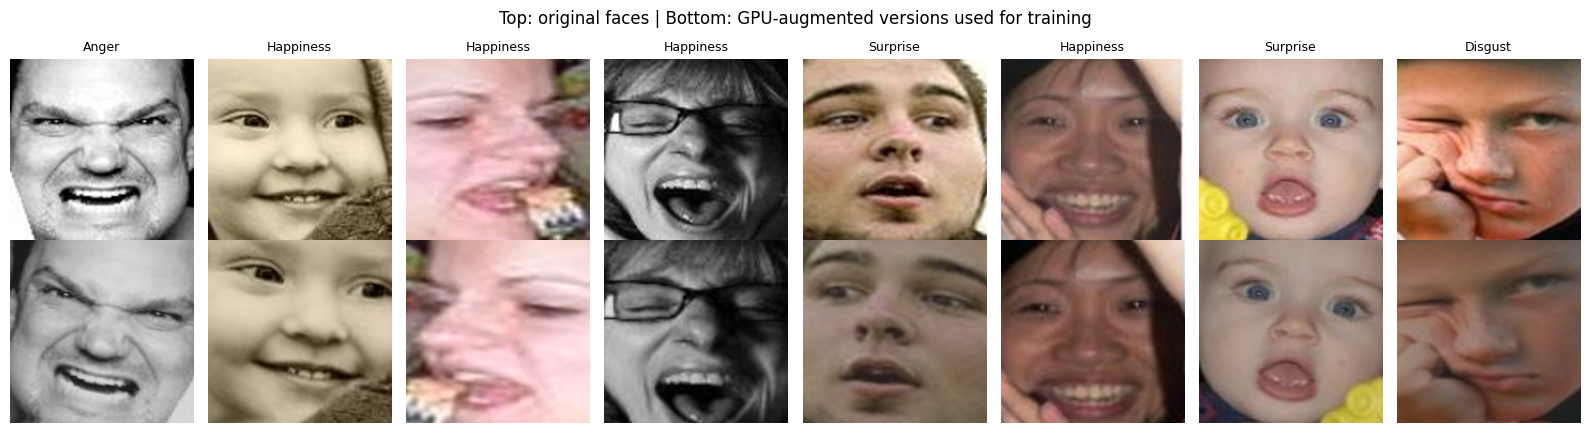

In [8]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def list_images(split_dir):
    items = []
    for c in range(1, 8):                                    # folders 1..7 -> labels 0..6
        for p in sorted((split_dir / str(c)).rglob('*')):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS and not p.name.startswith('._'):
                items.append((str(p), c - 1))
    return items

def read_one(item):
    path, label = item
    try:
        im = Image.open(path).convert('RGB').resize((STORE_SIZE, STORE_SIZE), Image.BICUBIC)
        return np.asarray(im, dtype=np.uint8), label, None
    except Exception:
        return None, label, path                             # corrupt / unreadable

def load_split(split_dir):
    items = list_images(split_dir)
    with ThreadPoolExecutor(8) as ex: res = list(ex.map(read_one, items))
    good = [(a, l) for a, l, b in res if b is None]; bad = [b for a, l, b in res if b is not None]
    X = torch.from_numpy(np.stack([a for a, _ in good])).permute(0, 3, 1, 2).contiguous()
    return X, np.array([l for _, l in good]), bad, len(items)

t0 = time.time()
X_all, y_all, bad_tr, n_tr = load_split(TRAIN_DIR)
X_te,  y_te,  bad_te, n_te = load_split(TEST_DIR)
print(f"Loaded in {time.time()-t0:.0f}s | train {len(y_all)}/{n_tr} (expected 12271) | test {len(y_te)}/{n_te} (expected 3068)")
for b in bad_tr + bad_te: print("  SKIPPED unreadable file:", b)
if len(bad_tr) + len(bad_te) > 20:
    print("Many unreadable files: the zip copy is probably damaged. Delete /content/rafdb_data and /content/rafdb.zip and run again.")

tr_idx, va_idx = train_test_split(np.arange(len(y_all)), test_size=VAL_FRACTION, stratify=y_all, random_state=SEED)
Xtr, ytr_np = X_all[tr_idx].to(DEVICE), y_all[tr_idx]
Xva, yv_np  = X_all[va_idx].to(DEVICE), y_all[va_idx]
Xte, yt_np  = X_te.to(DEVICE), y_te
ytr_t = torch.as_tensor(ytr_np, dtype=torch.long, device=DEVICE)
del X_all; gc.collect()

counts = np.bincount(ytr_np, minlength=NUM_CLASSES)
SAMPLE_W = torch.as_tensor(1.0 / (counts[ytr_np] ** SAMPLER_POWER), dtype=torch.float32, device=DEVICE)
print(pd.DataFrame({"Emotion": CLASSES, "Train": counts, "Val": np.bincount(yv_np, minlength=NUM_CLASSES),
                    "Test": np.bincount(yt_np, minlength=NUM_CLASSES)}).to_string(index=False))

# ---------------- GPU augmentation / preprocessing ----------------
def gpu_augment(xb):
    dev = xb.device; B = xb.size(0); x = xb.float() / 255.0
    u = lambda lo, hi, *shape: torch.empty(*shape, device=dev).uniform_(lo, hi)
    # geometry in ONE grid_sample: random zoom-crop + rotation + mirror + resize to IMG_SIZE
    z = u(0.84, 1.0, B); ang = u(-12, 12, B) * math.pi / 180
    flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = z * cos * flip; theta[:, 0, 1] = -z * sin; theta[:, 0, 2] = (torch.rand(B, device=dev) * 2 - 1) * (1 - z)
    theta[:, 1, 0] = z * sin * flip; theta[:, 1, 1] = z * cos;  theta[:, 1, 2] = (torch.rand(B, device=dev) * 2 - 1) * (1 - z)
    grid = F.affine_grid(theta, (B, 3, IMG_SIZE, IMG_SIZE), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    # colour jitter: brightness, contrast, saturation
    x = x * u(0.7, 1.3, B, 1, 1, 1)
    m = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - m) * u(0.7, 1.3, B, 1, 1, 1) + m
    g = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]; x = (x - g) * u(0.8, 1.2, B, 1, 1, 1) + g
    x = x.clamp(0, 1)
    # random erasing (25% of images)
    H = IMG_SIZE; area = u(0.02, 0.12, B) * H * H; ratio = u(0.5, 2.0, B)
    eh = torch.sqrt(area * ratio).clamp(max=H - 1); ew = torch.sqrt(area / ratio).clamp(max=H - 1)
    y0 = torch.rand(B, device=dev) * (H - eh); x0 = torch.rand(B, device=dev) * (H - ew)
    ys = torch.arange(H, device=dev).view(1, H, 1).float(); xs = torch.arange(H, device=dev).view(1, 1, H).float()
    mask = (ys >= y0.view(B, 1, 1)) & (ys < (y0 + eh).view(B, 1, 1)) & (xs >= x0.view(B, 1, 1)) & (xs < (x0 + ew).view(B, 1, 1))
    mask = mask & (torch.rand(B, device=dev) < 0.25).view(B, 1, 1)
    return torch.where(mask.unsqueeze(1), torch.full_like(x, 0.5), x)

def prep_eval(xb):
    x = xb.float() / 255.0
    return F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bicubic", align_corners=False).clamp(0, 1)

def iter_train(bs):
    idx = torch.multinomial(SAMPLE_W, len(SAMPLE_W), replacement=True)       # class-balanced (soft) sampling
    for i in range(0, len(idx) - bs + 1, bs):
        j = idx[i:i + bs]; yield gpu_augment(Xtr[j]), ytr_t[j]

# self-check + picture of what the augmentation does
with torch.no_grad(): demo = gpu_augment(Xtr[:8])
assert demo.shape == (8, 3, IMG_SIZE, IMG_SIZE) and 0 <= demo.min() and demo.max() <= 1, "augmentation self-check failed"
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    axes[0, i].imshow(prep_eval(Xtr[i:i+1])[0].permute(1, 2, 0).cpu().numpy()); axes[0, i].set_title(CLASSES[int(ytr_np[i])], fontsize=9)
    axes[1, i].imshow(demo[i].permute(1, 2, 0).cpu().numpy()); axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_ylabel("original"); plt.suptitle("Top: original faces | Bottom: GPU-augmented versions used for training"); plt.tight_layout(); plt.show()

In [9]:
class Norm(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("m", torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("s", torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1))
    def forward(self, x): return (x - self.m) / self.s

class EMA:
    def __init__(self, model, decay):
        self.ema = copy.deepcopy(model).eval(); self.decay = decay
        for p in self.ema.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point: v.mul_(self.decay).add_(msd[k].detach(), alpha=1 - self.decay)
            else: v.copy_(msd[k])

SPECS = {   # proven settings from your runs; epochs capped at 10
    "ViT-B-CLIP":    dict(tags=["vit_base_patch16_clip_224.openai_ft_in12k_in1k", "vit_base_patch16_224.augreg_in21k_ft_in1k"],
                          lr=1e-4, head_mult=1,  ld=0.75, bs=32, ema=0.999, ep=10),
    "BEiT-Base":     dict(tags=["beit_base_patch16_224.in22k_ft_in22k_in1k", "beit_base_patch16_224"],
                          lr=1e-4, head_mult=1,  ld=0.75, bs=32, ema=0.999, ep=10),
    "ConvNeXt-Tiny": dict(tags=["convnext_tiny"],
                          lr=5e-5, head_mult=10, ld=None, bs=64, ema=0.998, ep=10),
}
SEED_MODELS = ["ViT-B-CLIP", "ConvNeXt-Tiny"]      # retrained for every seed (Mean ± SD and seed averaging)

def autocast(): return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_CUDA)

@torch.no_grad()
def run_eval(model, X, y_np, bs=128):
    model.eval(); yt_ = torch.as_tensor(y_np, device=DEVICE); tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        with autocast(): out = model(prep_eval(X[i:i + bs]))
        tot += F.cross_entropy(out.float(), yt_[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == yt_[i:i + bs]).sum().item()
    return tot / len(X), correct / len(X)

def center_zoom(x, z):
    s = int(round(IMG_SIZE * z)); up = F.interpolate(x, size=(s, s), mode="bilinear", align_corners=False); o = (s - IMG_SIZE) // 2
    return up[:, :, o:o + IMG_SIZE, o:o + IMG_SIZE]

@torch.no_grad()
def predict_tta(model, X, bs=128):
    model.eval(); P = []
    for i in range(0, len(X), bs):
        x = prep_eval(X[i:i + bs]); acc = 0
        for z in ZOOMS:
            xz = x if z == 1.0 else center_zoom(x, z)
            for xi in (xz, torch.flip(xz, dims=[3])):
                with autocast(): acc = acc + F.softmax(model(xi).float(), 1)
        P.append((acc / N_VIEWS).cpu().numpy())
    return np.concatenate(P)

@torch.no_grad()
def forward_ms(model, reps=20):
    model.eval(); x = prep_eval(Xva[:64])
    for _ in range(3):
        with autocast(): model(x)
    if USE_CUDA: torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        with autocast(): model(x)
    if USE_CUDA: torch.cuda.synchronize()
    return (time.time() - t0) / (reps * x.size(0)) * 1000

def make_backbone(tags):
    for nm in tags:
        try:
            b = timm.create_model(nm, pretrained=True, num_classes=NUM_CLASSES, drop_path_rate=0.1); print("  loaded:", nm); return b, nm
        except Exception as e:
            print("  could not load", nm, "->", str(e)[:100])
    raise RuntimeError("no model could be loaded")

def train_spec(name, seed, wd=0.05, warmup=1, patience=5):
    sp = SPECS[name]; set_seed(seed); tag = f"{name}_s{seed}"; t_start = time.time(); epochs = sp["ep"]
    backbone, used = make_backbone(sp["tags"])
    cfg = timm.data.resolve_data_config({}, model=backbone)
    model = nn.Sequential(Norm(cfg["mean"], cfg["std"]), backbone).to(DEVICE)
    opt = None
    if sp["ld"]:     # layer-wise LR decay: lower layers change slowly, top layers faster
        try: opt = create_optimizer_v2(backbone, opt="adamw", lr=sp["lr"], weight_decay=wd, layer_decay=sp["ld"])
        except Exception as e: print("  layer decay unavailable:", str(e)[:80])
    if opt is None:
        head = list(backbone.get_classifier().parameters()); hid = {id(p) for p in head}
        body = [p for p in backbone.parameters() if id(p) not in hid]
        opt = optim.AdamW([{"params": body, "lr_scale": 1.0}, {"params": head, "lr_scale": float(sp["head_mult"])}], lr=sp["lr"], weight_decay=wd)
    mix = Mixup(mixup_alpha=0.2, cutmix_alpha=1.0, prob=0.3, label_smoothing=0.1, num_classes=NUM_CLASSES)
    crit = SoftTargetCrossEntropy(); scaler = torch.amp.GradScaler("cuda", enabled=USE_CUDA); ema = EMA(model, sp["ema"])
    spe = len(Xtr) // sp["bs"]; total, warm = epochs * spe, warmup * spe
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}; best_acc, best_state, bad, step = -1.0, None, 0, 0
    for ep in range(1, epochs + 1):
        model.train(); tl, tn, t0 = 0.0, 0, time.time()
        for x, y in iter_train(sp["bs"]):
            f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm))); f = max(f, 0.02)
            for g in opt.param_groups: g["lr"] = sp["lr"] * f * g.get("lr_scale", 1.0)
            x, ys = mix(x, y)
            with autocast(): loss = crit(model(x).float(), ys)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); ema.update(model); step += 1
            tl += loss.item() * y.size(0); tn += y.size(0)
        vl, va = run_eval(ema.ema, Xva, yv_np)
        for k, v in zip(hist, (tl / tn, vl, va)): hist[k].append(v)
        flag = ""
        if va > best_acc: best_acc, bad, flag = va, 0, " *best"; best_state = {k: v.detach().cpu().clone() for k, v in ema.ema.state_dict().items()}
        else: bad += 1
        print(f"  [{tag}] ep {ep:02d}/{epochs} | loss {tl/tn:.3f} | val acc {va:.4f} | {time.time()-t0:.0f}s{flag}")
        if bad >= patience: print("  early stop"); break
    model.load_state_dict(best_state); train_s = time.time() - t_start
    print(f"  [{tag}] done in {train_s/60:.1f} min | best val acc {best_acc:.4f}")
    torch.save({"name": name, "timm": used, "state_dict": model.state_dict(), "hist": hist, "train_s": train_s, "classes": CLASSES},
               f"{CKPT_DIR}/{tag}.pt")
    del opt, ema; gc.collect()
    if USE_CUDA: torch.cuda.empty_cache()
    return model, hist, train_s

def load_ckpt(path):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    bb = timm.create_model(ck["timm"], pretrained=False, num_classes=NUM_CLASSES, drop_path_rate=0.1)
    cfg = timm.data.resolve_data_config({}, model=bb)
    m = nn.Sequential(Norm(cfg["mean"], cfg["std"]), bb); m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval(), ck["hist"], ck["train_s"]

STORE_PATH = f"{CKPT_DIR}/run_store.pkl"
RUN_STORE = pickle.load(open(STORE_PATH, "rb")) if os.path.exists(STORE_PATH) else {}   # key = (model, seed); seed -1 = your previous run
def save_store(): pickle.dump(RUN_STORE, open(STORE_PATH, "wb"))

def run_one(name, seed):
    key = (name, seed)
    if key in RUN_STORE: return
    ck = f"{CKPT_DIR}/{name}_s{seed}.pt"
    if os.path.exists(ck): model, hist, ts = load_ckpt(ck); print(f"reloaded {name} seed {seed} from Drive")
    else: model, hist, ts = train_spec(name, seed)
    RUN_STORE[key] = {"val": predict_tta(model, Xva), "test": predict_tta(model, Xte), "train_s": ts, "fwd_ms": forward_ms(model), "hist": hist}
    save_store(); del model; gc.collect()
    if USE_CUDA: torch.cuda.empty_cache()

print("Training engine ready. Already stored:", sorted(RUN_STORE))

Training engine ready. Already stored: []


## 3. Seed-42 models (and reuse of your earlier results)

In [10]:
# --- reuse predictions from your earlier notebook (same split, same TTA) so nothing is trained twice ---
if REUSE_PREVIOUS and os.path.exists(PREV_STORE):
    prev = pickle.load(open(PREV_STORE, "rb"))
    for nm in ["ViT-B-CLIP", "BEiT-Base", "ConvNeXt-Tiny"]:
        if nm in prev and (nm, -1) not in RUN_STORE:
            p = prev[nm]; acc = accuracy_score(yt_np, p["test"].argmax(1))
            assert p["test"].shape[0] == len(yt_np) and acc > 0.7, f"{nm}: earlier results do not match this data split (test acc {acc:.3f})"
            RUN_STORE[(nm, -1)] = {"val": p["val"], "test": p["test"], "train_s": p["train_s"], "fwd_ms": p["fwd_ms"], "hist": None}
            print(f"reused earlier {nm}: test accuracy {acc:.4f}")
    save_store()
else:
    print("No earlier store reused (BEiT-Base will be trained here).")

for name in SEED_MODELS: run_one(name, SEED)                               # new 10-epoch recipe, seed 42
for name in SPECS:                                                         # backbones with no results yet (e.g. BEiT-Base without an earlier store)
    if not any(k[0] == name for k in RUN_STORE): run_one(name, SEED)

lab = lambda k: f"{k[0]} ({'previous run' if k[1] < 0 else 'seed ' + str(k[1])})"
print(pd.DataFrame({lab(k): {"Val acc": accuracy_score(yv_np, v["val"].argmax(1)), "Test acc": accuracy_score(yt_np, v["test"].argmax(1)),
                             "Train min": v["train_s"] / 60} for k, v in sorted(RUN_STORE.items())}).T.round(4).to_string())

No earlier store reused (BEiT-Base will be trained here).


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

  loaded: vit_base_patch16_clip_224.openai_ft_in12k_in1k
  [ViT-B-CLIP_s42] ep 01/10 | loss 1.361 | val acc 0.4927 | 102s *best
  [ViT-B-CLIP_s42] ep 02/10 | loss 1.001 | val acc 0.7101 | 102s *best
  [ViT-B-CLIP_s42] ep 03/10 | loss 0.863 | val acc 0.7972 | 101s *best
  [ViT-B-CLIP_s42] ep 04/10 | loss 0.825 | val acc 0.8436 | 101s *best
  [ViT-B-CLIP_s42] ep 05/10 | loss 0.733 | val acc 0.8567 | 101s *best
  [ViT-B-CLIP_s42] ep 06/10 | loss 0.714 | val acc 0.8697 | 101s *best
  [ViT-B-CLIP_s42] ep 07/10 | loss 0.678 | val acc 0.8779 | 101s *best
  [ViT-B-CLIP_s42] ep 08/10 | loss 0.685 | val acc 0.8811 | 101s *best
  [ViT-B-CLIP_s42] ep 09/10 | loss 0.681 | val acc 0.8811 | 101s
  [ViT-B-CLIP_s42] ep 10/10 | loss 0.632 | val acc 0.8803 | 101s
  [ViT-B-CLIP_s42] done in 17.1 min | best val acc 0.8811


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  loaded: convnext_tiny
  [ConvNeXt-Tiny_s42] ep 01/10 | loss 1.477 | val acc 0.4406 | 78s *best
  [ConvNeXt-Tiny_s42] ep 02/10 | loss 1.137 | val acc 0.6938 | 54s *best
  [ConvNeXt-Tiny_s42] ep 03/10 | loss 0.961 | val acc 0.7712 | 54s *best
  [ConvNeXt-Tiny_s42] ep 04/10 | loss 0.899 | val acc 0.8029 | 54s *best
  [ConvNeXt-Tiny_s42] ep 05/10 | loss 0.787 | val acc 0.8225 | 54s *best
  [ConvNeXt-Tiny_s42] ep 06/10 | loss 0.720 | val acc 0.8331 | 54s *best
  [ConvNeXt-Tiny_s42] ep 07/10 | loss 0.710 | val acc 0.8436 | 54s *best
  [ConvNeXt-Tiny_s42] ep 08/10 | loss 0.714 | val acc 0.8534 | 54s *best
  [ConvNeXt-Tiny_s42] ep 09/10 | loss 0.646 | val acc 0.8599 | 54s *best
  [ConvNeXt-Tiny_s42] ep 10/10 | loss 0.634 | val acc 0.8616 | 54s *best
  [ConvNeXt-Tiny_s42] done in 9.4 min | best val acc 0.8616


model.safetensors: reconstructing file:   0%|          |  0.00B /  350MB            

model.safetensors: downloading bytes:           |  0.00B            

  loaded: beit_base_patch16_224.in22k_ft_in22k_in1k
  [BEiT-Base_s42] ep 01/10 | loss 1.490 | val acc 0.6303 | 113s *best
  [BEiT-Base_s42] ep 02/10 | loss 1.045 | val acc 0.7248 | 112s *best
  [BEiT-Base_s42] ep 03/10 | loss 0.907 | val acc 0.7923 | 112s *best
  [BEiT-Base_s42] ep 04/10 | loss 0.852 | val acc 0.8265 | 112s *best
  [BEiT-Base_s42] ep 05/10 | loss 0.760 | val acc 0.8428 | 112s *best
  [BEiT-Base_s42] ep 06/10 | loss 0.748 | val acc 0.8567 | 112s *best
  [BEiT-Base_s42] ep 07/10 | loss 0.710 | val acc 0.8599 | 112s *best
  [BEiT-Base_s42] ep 08/10 | loss 0.722 | val acc 0.8632 | 112s *best
  [BEiT-Base_s42] ep 09/10 | loss 0.717 | val acc 0.8656 | 112s *best
  [BEiT-Base_s42] ep 10/10 | loss 0.666 | val acc 0.8656 | 112s
  [BEiT-Base_s42] done in 18.8 min | best val acc 0.8656
                         Val acc  Test acc  Train min
BEiT-Base (seed 42)       0.8689    0.8801    18.8268
ConvNeXt-Tiny (seed 42)   0.8681    0.8781     9.3929
ViT-B-CLIP (seed 42)      0.8876   

## 4. More seeds: Mean ± SD across 5 runs and seed ensembling

ViT-B-CLIP and ConvNeXt-Tiny are retrained with seeds 43, 44, 45, 46 (same 10-epoch recipe as seed 42, so the five runs are directly comparable). This gives (a) the **Mean ± SD across 5 runs** and (b) a pool of independently trained models whose average is more accurate and more stable than any single run.

In [11]:
for seed in SEEDS[1:]:
    for name in SEED_MODELS:
        run_one(name, seed)
print("stored models:", len(RUN_STORE))

  loaded: vit_base_patch16_clip_224.openai_ft_in12k_in1k
  [ViT-B-CLIP_s43] ep 01/10 | loss 1.376 | val acc 0.3950 | 101s *best
  [ViT-B-CLIP_s43] ep 02/10 | loss 0.988 | val acc 0.7109 | 102s *best
  [ViT-B-CLIP_s43] ep 03/10 | loss 0.871 | val acc 0.7997 | 101s *best
  [ViT-B-CLIP_s43] ep 04/10 | loss 0.820 | val acc 0.8428 | 101s *best
  [ViT-B-CLIP_s43] ep 05/10 | loss 0.771 | val acc 0.8599 | 101s *best
  [ViT-B-CLIP_s43] ep 06/10 | loss 0.714 | val acc 0.8681 | 101s *best
  [ViT-B-CLIP_s43] ep 07/10 | loss 0.670 | val acc 0.8779 | 101s *best
  [ViT-B-CLIP_s43] ep 08/10 | loss 0.659 | val acc 0.8811 | 101s *best
  [ViT-B-CLIP_s43] ep 09/10 | loss 0.675 | val acc 0.8803 | 101s
  [ViT-B-CLIP_s43] ep 10/10 | loss 0.669 | val acc 0.8787 | 101s
  [ViT-B-CLIP_s43] done in 16.9 min | best val acc 0.8811
  loaded: convnext_tiny
  [ConvNeXt-Tiny_s43] ep 01/10 | loss 1.501 | val acc 0.2964 | 54s *best
  [ConvNeXt-Tiny_s43] ep 02/10 | loss 1.106 | val acc 0.6417 | 54s *best
  [ConvNeXt-Tiny_

## 5. Metrics helper and Mean ± SD

Mean ± SD (sample SD) across seeds | inference time includes 4 TTA views per image


,Runs,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,ROC-AUC (OvR),MCC,Train Time (min),Inference (ms/img)
Model,,,,,,,,,,,,
ViT-B-CLIP,5,0.8934 ± 0.0028,0.8353 ± 0.0047,0.8259 ± 0.0065,0.8300 ± 0.0033,0.8934 ± 0.0025,0.8934 ± 0.0028,0.8931 ± 0.0025,0.9786 ± 0.0015,0.8599 ± 0.0035,16.97 ± 0.06,9.72 ± 0.02
ConvNeXt-Tiny,5,0.8786 ± 0.0016,0.8176 ± 0.0034,0.8130 ± 0.0052,0.8148 ± 0.0040,0.8803 ± 0.0012,0.8786 ± 0.0016,0.8792 ± 0.0014,0.9740 ± 0.0024,0.8406 ± 0.0020,9.06 ± 0.19,5.99 ± 0.01
Run ensemble,5,0.8985 ± 0.0018,0.8442 ± 0.0051,0.8338 ± 0.0043,0.8385 ± 0.0037,0.8986 ± 0.0013,0.8985 ± 0.0018,0.8983 ± 0.0015,0.9828 ± 0.0017,0.8666 ± 0.0022,26.03 ± 0.25,15.71 ± 0.02


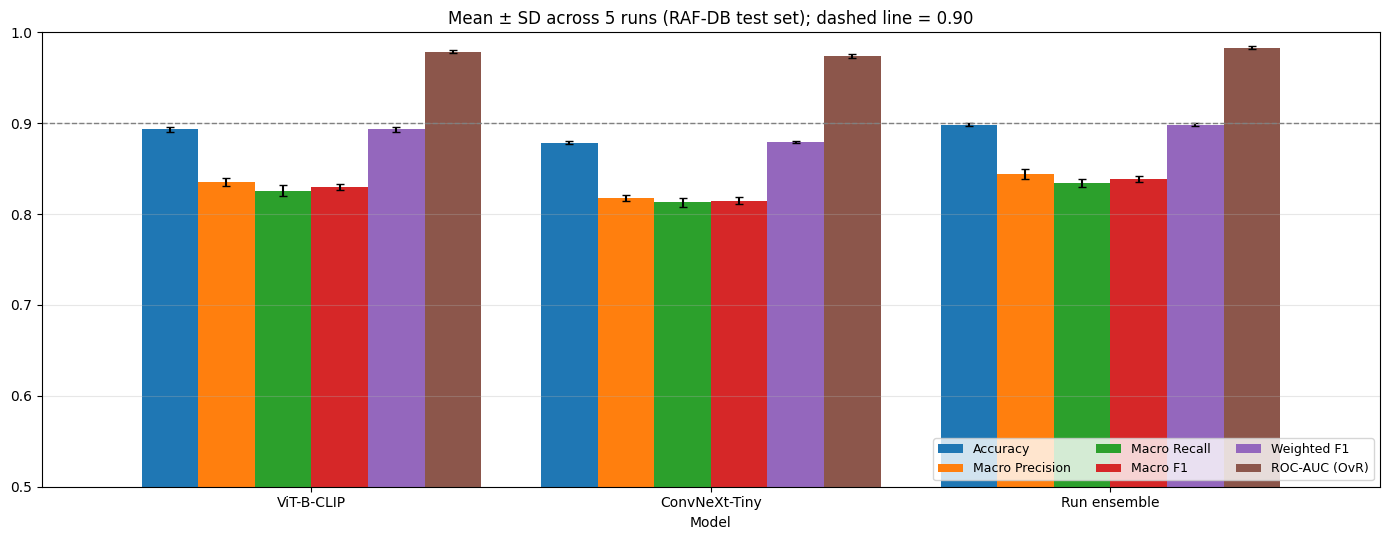

In [12]:
def norm64(P): P = np.asarray(P, dtype=np.float64); return P / P.sum(1, keepdims=True)

def full_metrics(y, P):
    P = norm64(P); pr = P.argmax(1); d = {"Accuracy": accuracy_score(y, pr)}
    for avg, tag in (("macro", "Macro"), ("weighted", "Weighted")):
        d[f"{tag} Precision"] = precision_score(y, pr, average=avg, zero_division=0)
        d[f"{tag} Recall"]    = recall_score(y, pr, average=avg, zero_division=0)
        d[f"{tag} F1"]        = f1_score(y, pr, average=avg, zero_division=0)
    d["ROC-AUC (OvR)"] = roc_auc_score(y, P, multi_class="ovr", average="macro"); d["MCC"] = matthews_corrcoef(y, pr)
    return d

def vll(P): return log_loss(yv_np, np.clip(P, 1e-7, 1), labels=range(NUM_CLASSES))

rows = []
for seed in SEEDS:
    avail = [n for n in SEED_MODELS if (n, seed) in RUN_STORE]
    for n in avail:
        s = RUN_STORE[(n, seed)]
        rows.append({"Model": n, "Seed": seed, **full_metrics(yt_np, s["test"]), "Train Time (min)": s["train_s"] / 60, "Inference (ms/img)": s["fwd_ms"] * N_VIEWS})
    bw, bk = None, 1e9                                       # this run's ensemble: weights picked on validation log-loss
    for w in itertools.product(range(4), repeat=len(avail)):
        if sum(w) == 0: continue
        k = vll(sum(wi * RUN_STORE[(n, seed)]["val"] for wi, n in zip(w, avail)) / sum(w))
        if k < bk: bw, bk = w, k
    used = [n for wi, n in zip(bw, avail) if wi > 0]
    Pt = sum(wi * RUN_STORE[(n, seed)]["test"] for wi, n in zip(bw, avail)) / sum(bw)
    rows.append({"Model": "Run ensemble", "Seed": seed, **full_metrics(yt_np, Pt),
                 "Train Time (min)": sum(RUN_STORE[(n, seed)]["train_s"] for n in used) / 60,
                 "Inference (ms/img)": sum(RUN_STORE[(n, seed)]["fwd_ms"] for n in used) * N_VIEWS})
runs_df = pd.DataFrame(rows); runs_df.to_csv(f"{OUT_DIR}/per_run_metrics.csv", index=False)

metric_cols = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted Precision", "Weighted Recall", "Weighted F1",
               "ROC-AUC (OvR)", "MCC", "Train Time (min)", "Inference (ms/img)"]
order = [m for m in SEED_MODELS if m in set(runs_df.Model)] + ["Run ensemble"]
mean_df = runs_df.groupby("Model")[metric_cols].mean().loc[order]; std_df = runs_df.groupby("Model")[metric_cols].std(ddof=1).loc[order]
summary = mean_df.copy().astype(object)
for c in metric_cols:
    d = 2 if ("Time" in c or "ms" in c) else 4
    summary[c] = [f"{m:.{d}f} ± {s:.{d}f}" for m, s in zip(mean_df[c], std_df[c])]
summary.insert(0, "Runs", runs_df.groupby("Model").size().loc[order])
print(f"Mean ± SD (sample SD) across seeds | inference time includes {N_VIEWS} TTA views per image")
display(summary); summary.to_csv(f"{OUT_DIR}/mean_sd_summary.csv")

plot_cols = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1", "ROC-AUC (OvR)"]
ax = mean_df[plot_cols].plot(kind="bar", yerr=std_df[plot_cols], capsize=3, figsize=(14, 5.5), rot=0, width=0.85)
ax.set_ylim(0.5, 1.0); ax.axhline(0.90, ls="--", c="gray", lw=1); ax.grid(axis="y", alpha=0.3)
ax.set_title(f"Mean ± SD across {len(SEEDS)} runs (RAF-DB test set); dashed line = 0.90"); ax.legend(ncol=3, fontsize=9, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/mean_sd_chart.png", dpi=200); plt.show()

## 6. Four ensembling modes

Built from the pool of all trained models. Weights, selection and the stacking meta-model use **validation data only**.

| Mode | Idea |
|---|---|
| Soft vote (equal) | average the seed-averaged probabilities of all four backbones |
| Soft vote (greedy weighted) | models are added one at a time (with replacement) while **validation log-loss** improves |
| Hard vote | majority vote of every trained model |
| Stacking (LogReg) | logistic regression learns how much to trust each backbone; regularisation chosen by cross-validation |

In [13]:
keys = sorted(RUN_STORE)
backbones = list(SPECS)
bb_v = {b: np.mean([RUN_STORE[k]["val"]  for k in keys if k[0] == b], 0) for b in backbones}     # seed-averaged probabilities
bb_t = {b: np.mean([RUN_STORE[k]["test"] for k in keys if k[0] == b], 0) for b in backbones}
n_seeds = {b: sum(1 for k in keys if k[0] == b) for b in backbones}
fwd_all, tr_all = {k: RUN_STORE[k]["fwd_ms"] * N_VIEWS for k in keys}, {k: RUN_STORE[k]["train_s"] for k in keys}

ENS_T, ENS_TIME = {}, {}
# 1) soft vote (equal)
ENS_T["Soft vote (equal)"] = np.mean([bb_t[b] for b in backbones], 0); ENS_TIME["Soft vote (equal)"] = (sum(tr_all.values()), sum(fwd_all.values()))

# 2) soft vote (greedy weighted over every stored model)
pool_v = {f"{k[0]}|s{k[1]}": RUN_STORE[k]["val"] for k in keys}; pool_t = {f"{k[0]}|s{k[1]}": RUN_STORE[k]["test"] for k in keys}
chosen, cur_v, best = [], None, 1e9
for _ in range(30):
    cand = None
    for k, P in pool_v.items():
        p = (cur_v * len(chosen) + P) / (len(chosen) + 1) if chosen else P; l = vll(p)
        if cand is None or l < cand[0]: cand = (l, k, p)
    if cand[0] >= best - 1e-5: break
    best, cur_v = cand[0], cand[2]; chosen.append(cand[1])
sel = Counter(chosen); print("greedy selection (model|seed: weight):", dict(sel))
ENS_T["Soft vote (greedy weighted)"] = sum(pool_t[k] * c for k, c in sel.items()) / sum(sel.values())
key_of = lambda s: (s.split("|s")[0], int(s.split("|s")[1]))
ENS_TIME["Soft vote (greedy weighted)"] = (sum(tr_all[key_of(k)] for k in sel), sum(fwd_all[key_of(k)] for k in sel))

# 3) hard vote over every stored model
votes = np.zeros_like(bb_t[backbones[0]])
for k in keys: votes[np.arange(len(votes)), RUN_STORE[k]["test"].argmax(1)] += 1
ENS_T["Hard vote"] = norm64(votes / len(keys) + 1e-3 * np.mean([RUN_STORE[k]["test"] for k in keys], 0)); ENS_TIME["Hard vote"] = ENS_TIME["Soft vote (equal)"]

# 4) stacking on the log of the seed-averaged backbone probabilities
feat = lambda d: np.hstack([np.log(np.clip(d[b], 1e-6, 1)) for b in backbones])
Xv_s, Xt_s = feat(bb_v), feat(bb_t); cv = StratifiedKFold(5, shuffle=True, random_state=SEED); best_s = None
for C in [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]:
    p_cv = cross_val_predict(LogisticRegression(C=C, max_iter=3000), Xv_s, yv_np, cv=cv, method="predict_proba")
    ll = log_loss(yv_np, p_cv, labels=range(NUM_CLASSES)); print(f"  stacking C={C}: CV log-loss {ll:.4f} | CV acc {accuracy_score(yv_np, p_cv.argmax(1)):.4f}")
    if best_s is None or ll < best_s[0]: best_s = (ll, C)
stacker = LogisticRegression(C=best_s[1], max_iter=3000).fit(Xv_s, yv_np)
ENS_T["Stacking (LogReg)"] = stacker.predict_proba(Xt_s); ENS_TIME["Stacking (LogReg)"] = ENS_TIME["Soft vote (equal)"]

print("\nTEST accuracy of each ensembling mode:")
for k, P in ENS_T.items(): print(f"  {k:28s} {accuracy_score(yt_np, P.argmax(1)):.4f}")
n90 = sum(accuracy_score(yt_np, P.argmax(1)) >= 0.90 for P in ENS_T.values())
print(f"\nModes at or above 0.90 accuracy: {n90} of {len(ENS_T)}")

greedy selection (model|seed: weight): {'ViT-B-CLIP|s45': 2, 'ViT-B-CLIP|s42': 1, 'ConvNeXt-Tiny|s45': 1, 'ViT-B-CLIP|s44': 1, 'ViT-B-CLIP|s46': 1}
  stacking C=0.003: CV log-loss 0.4464 | CV acc 0.8844
  stacking C=0.01: CV log-loss 0.3698 | CV acc 0.8909
  stacking C=0.03: CV log-loss 0.3513 | CV acc 0.8925
  stacking C=0.1: CV log-loss 0.3543 | CV acc 0.8917
  stacking C=0.3: CV log-loss 0.3714 | CV acc 0.8876
  stacking C=1.0: CV log-loss 0.4009 | CV acc 0.8819

TEST accuracy of each ensembling mode:
  Soft vote (equal)            0.8996
  Soft vote (greedy weighted)  0.9032
  Hard vote                    0.9025
  Stacking (LogReg)            0.8950

Modes at or above 0.90 accuracy: 2 of 4


## 7. Full evaluation on the test set

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,ROC-AUC (OvR),MCC,Train Time (min),Inference (ms/img)
0,Ens: Soft vote (greedy weighted),0.9032,0.8492,0.8341,0.8410,0.9027,0.9032,0.9026,0.9858,0.8727,76.8998,44.8875
1,Ens: Hard vote,0.9025,0.8496,0.8405,0.8448,0.9029,0.9025,0.9025,0.9863,0.8720,148.9605,88.7909
2,ViT-B-CLIP (5-run avg),0.9003,0.8441,0.8350,0.8391,0.9003,0.9003,0.9000,0.9856,0.8690,84.8575,48.6037
3,Ens: Soft vote (equal),0.8996,0.8435,0.8316,0.8371,0.8997,0.8996,0.8994,0.9867,0.8681,148.9605,88.7909
4,Ens: Stacking (LogReg),0.8950,0.8416,0.8166,0.8264,0.8951,0.8950,0.8944,0.9833,0.8620,148.9605,88.7909
5,ViT-B-CLIP (seed 42),0.8944,0.8395,0.8292,0.8335,0.8946,0.8944,0.8942,0.9775,0.8613,17.0813,9.7017
6,ConvNeXt-Tiny (5-run avg),0.8856,0.8290,0.8199,0.8237,0.8874,0.8856,0.8861,0.9788,0.8499,45.2762,29.9316
7,BEiT-Base (seed 42),0.8801,0.8161,0.8130,0.8144,0.8810,0.8801,0.8804,0.9805,0.8426,18.8268,10.2556
8,ConvNeXt-Tiny (seed 42),0.8781,0.8203,0.8150,0.8170,0.8798,0.8781,0.8787,0.9738,0.8400,9.3929,5.9863


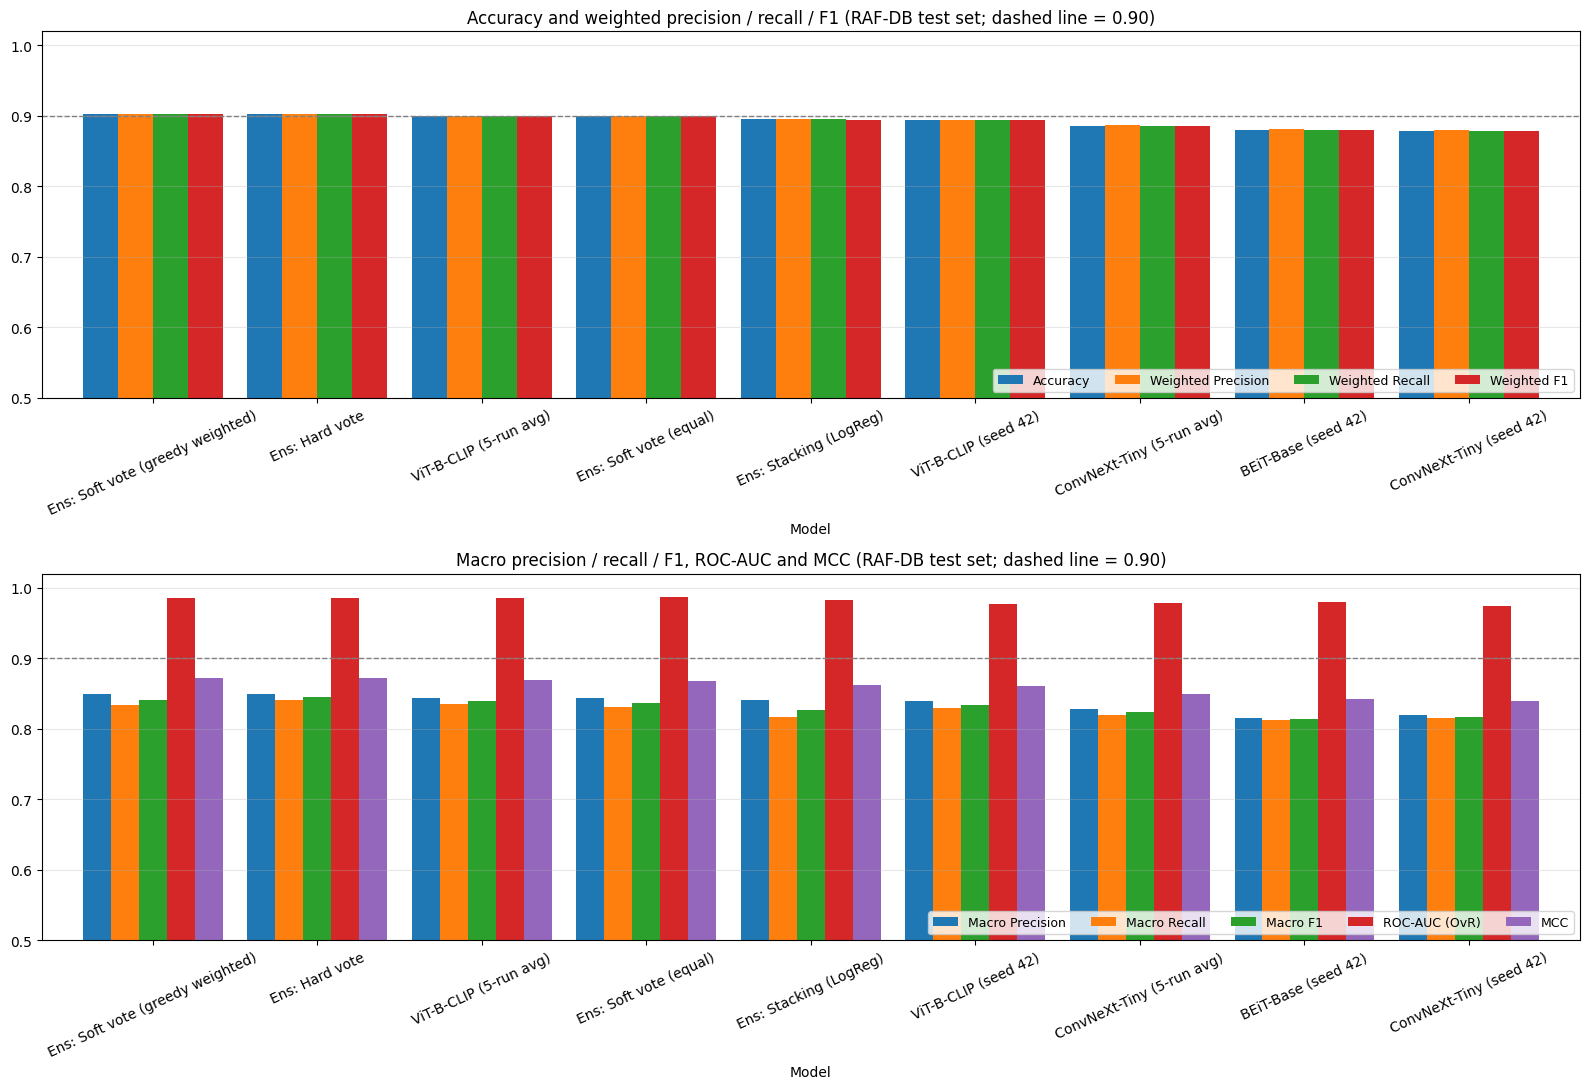

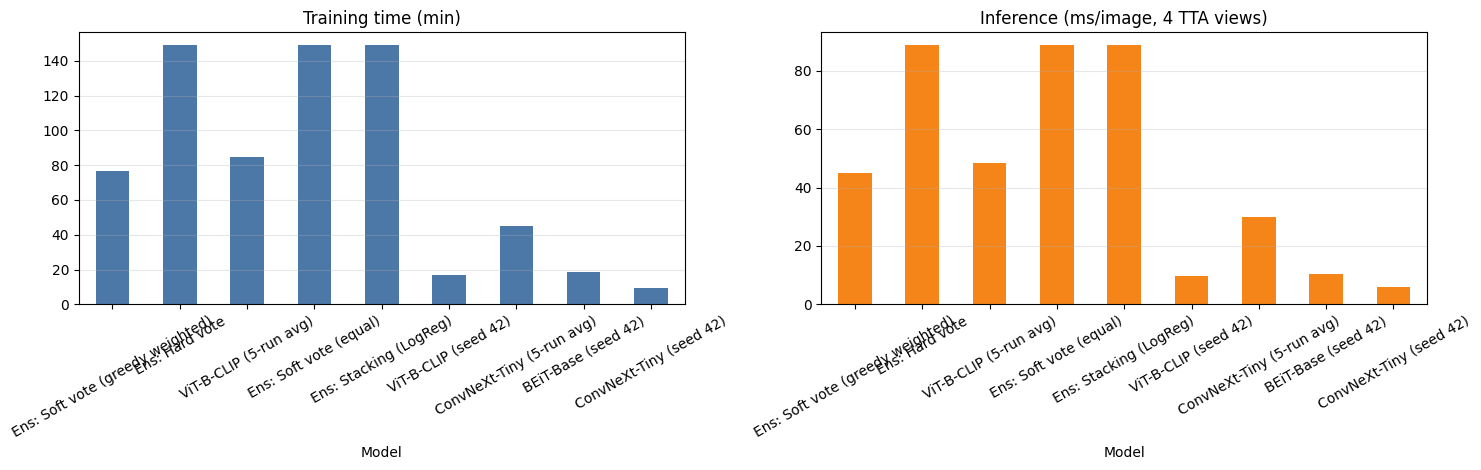

In [14]:
EVAL_P, TT, II = {}, {}, {}
for k in keys:
    if k[1] in (SEED, -1):                                   # single trained runs (new seed-42 run and your previous run)
        nm = lab(k); EVAL_P[nm] = RUN_STORE[k]["test"]; TT[nm] = tr_all[k]; II[nm] = fwd_all[k]
for b in backbones:
    if n_seeds[b] > 1:
        nm = f"{b} ({n_seeds[b]}-run avg)"; EVAL_P[nm] = bb_t[b]
        TT[nm] = sum(tr_all[k] for k in keys if k[0] == b); II[nm] = sum(fwd_all[k] for k in keys if k[0] == b)
for k, P in ENS_T.items():
    nm = f"Ens: {k}"; EVAL_P[nm] = P; TT[nm], II[nm] = ENS_TIME[k]

rows = [{"Model": n, **full_metrics(yt_np, P), "Train Time (min)": TT[n] / 60, "Inference (ms/img)": II[n]} for n, P in EVAL_P.items()]
metrics_df = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(metrics_df.round(4)); metrics_df.to_csv(f"{OUT_DIR}/full_metrics.csv", index=False)

t = metrics_df.set_index("Model")
fig, axes = plt.subplots(2, 1, figsize=(16, 11))
for ax, cols, ttl in [(axes[0], ["Accuracy", "Weighted Precision", "Weighted Recall", "Weighted F1"], "Accuracy and weighted precision / recall / F1"),
                      (axes[1], ["Macro Precision", "Macro Recall", "Macro F1", "ROC-AUC (OvR)", "MCC"], "Macro precision / recall / F1, ROC-AUC and MCC")]:
    t[cols].plot(kind="bar", ax=ax, rot=25, width=0.85); ax.set_ylim(0.5, 1.02); ax.axhline(0.90, ls="--", c="gray", lw=1)
    ax.grid(axis="y", alpha=0.3); ax.set_title(ttl + " (RAF-DB test set; dashed line = 0.90)"); ax.legend(ncol=5, fontsize=9, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/metrics_chart.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
t["Train Time (min)"].plot(kind="bar", ax=axes[0], color="#4C78A8", rot=30); axes[0].set_title("Training time (min)")
t["Inference (ms/img)"].plot(kind="bar", ax=axes[1], color="#F58518", rot=30); axes[1].set_title(f"Inference (ms/image, {N_VIEWS} TTA views)")
for a in axes: a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/time_chart.png", dpi=200); plt.show()

### Per-class scores, confusion matrices, ROC curves, training curves

Per-class precision / recall / F1: Ens: Soft vote (greedy weighted)


,Class,Precision,Recall,F1,Support
0,Surprise,0.9052,0.8997,0.9024,329
1,Fear,0.7206,0.6622,0.6901,74
2,Disgust,0.7518,0.6625,0.7043,160
3,Happiness,0.9700,0.9561,0.9630,1185
4,Sadness,0.8745,0.9038,0.8889,478
5,Anger,0.8509,0.8457,0.8483,162
6,Neutral,0.8717,0.9088,0.8898,680


              precision    recall  f1-score   support

    Surprise     0.9052    0.8997    0.9024       329
        Fear     0.7206    0.6622    0.6901        74
     Disgust     0.7518    0.6625    0.7043       160
   Happiness     0.9700    0.9561    0.9630      1185
     Sadness     0.8745    0.9038    0.8889       478
       Anger     0.8509    0.8457    0.8483       162
     Neutral     0.8717    0.9088    0.8898       680

    accuracy                         0.9032      3068
   macro avg     0.8492    0.8341    0.8410      3068
weighted avg     0.9027    0.9032    0.9026      3068



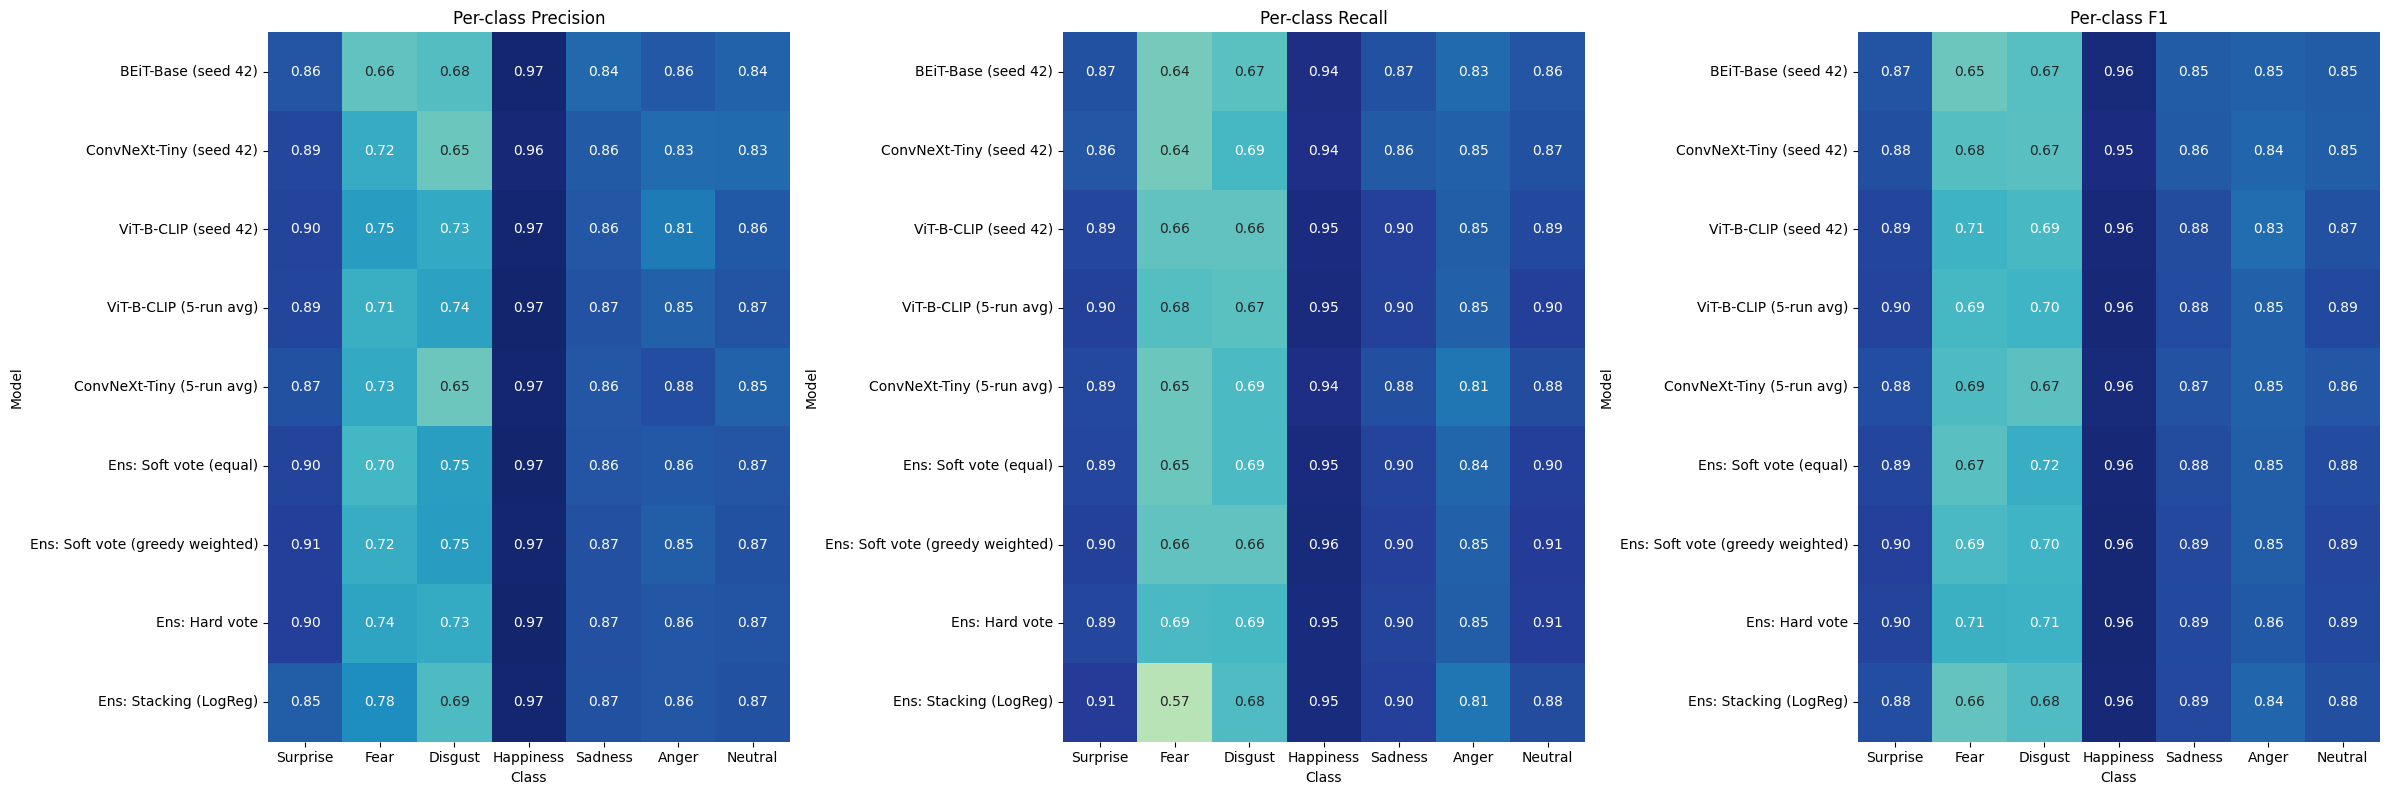

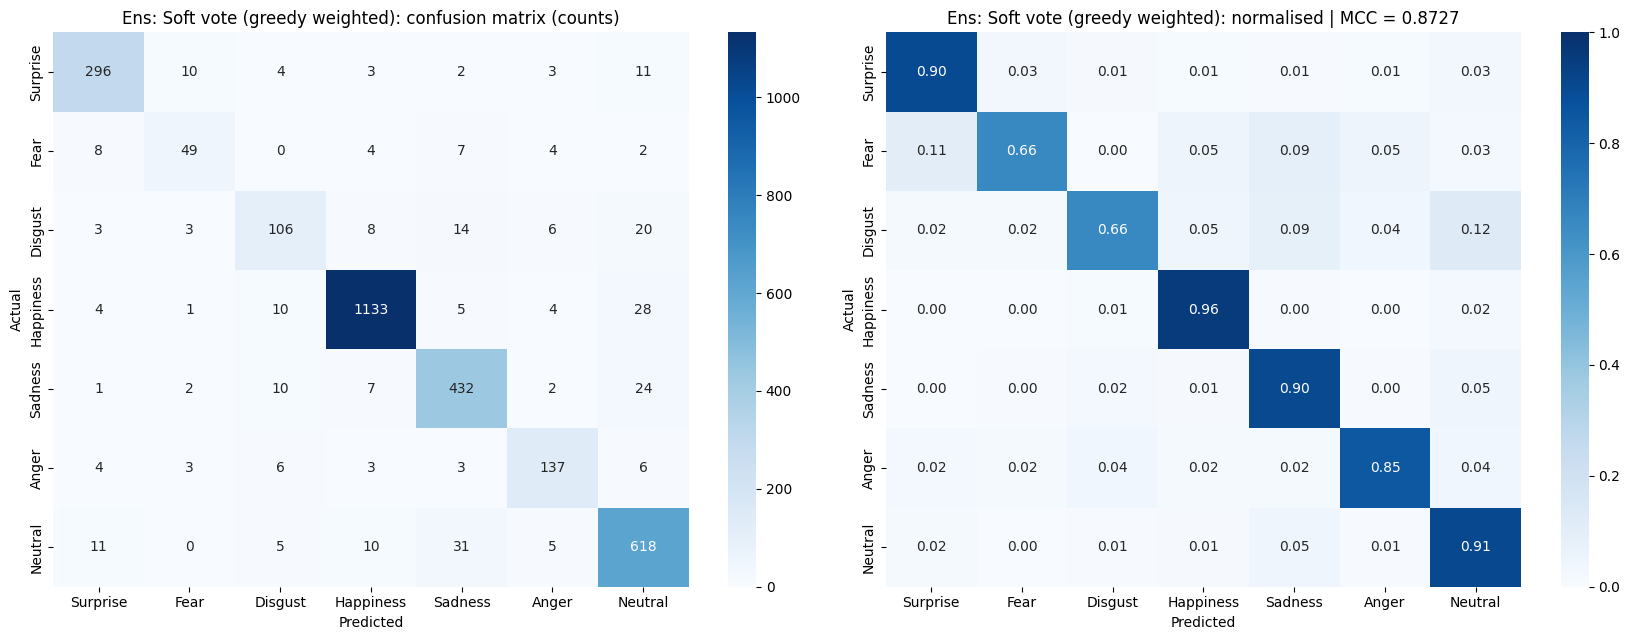

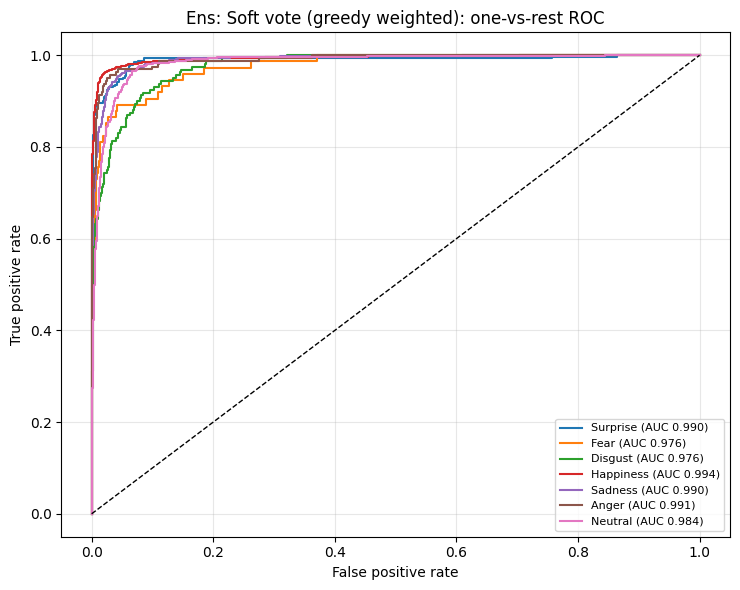

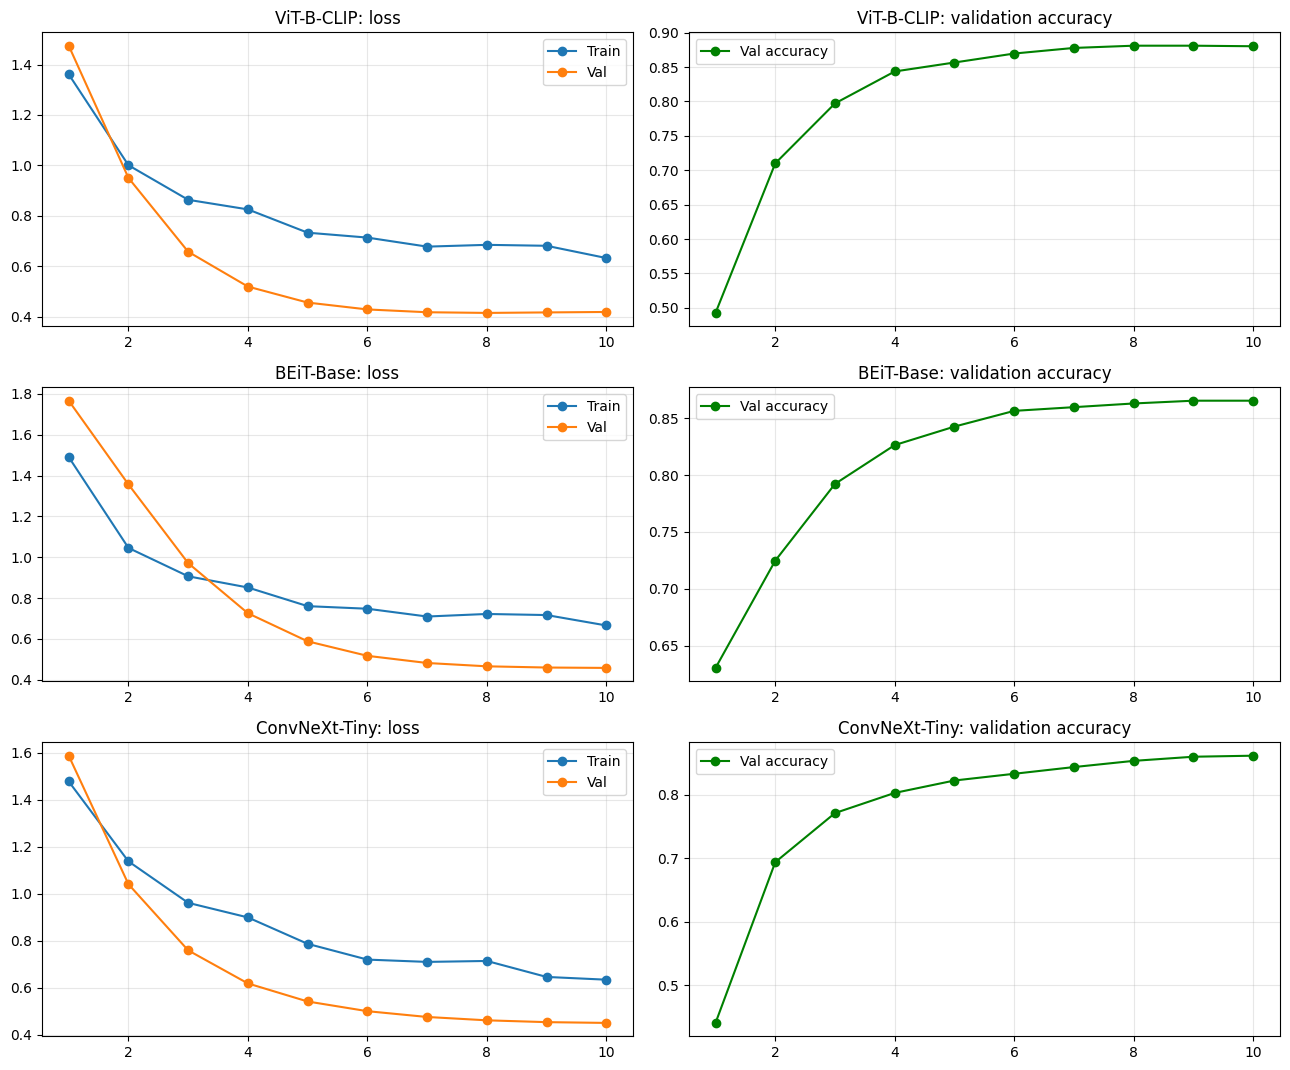

In [15]:
best_ens = max(ENS_T, key=lambda k: accuracy_score(yt_np, ENS_T[k].argmax(1))); BEST = f"Ens: {best_ens}"
pc = []
for n, P in EVAL_P.items():
    p, r, f, s = precision_recall_fscore_support(yt_np, P.argmax(1), labels=range(NUM_CLASSES), zero_division=0)
    for i, c in enumerate(CLASSES): pc.append({"Model": n, "Class": c, "Precision": p[i], "Recall": r[i], "F1": f[i], "Support": s[i]})
per_class_df = pd.DataFrame(pc); per_class_df.to_csv(f"{OUT_DIR}/per_class_metrics.csv", index=False)
print("Per-class precision / recall / F1:", BEST); display(per_class_df[per_class_df.Model == BEST].drop(columns="Model").round(4).reset_index(drop=True))
print(classification_report(yt_np, EVAL_P[BEST].argmax(1), target_names=CLASSES, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(24, 0.45 * len(EVAL_P) + 4))
for ax, m in zip(axes, ["Precision", "Recall", "F1"]):
    pv = per_class_df.pivot(index="Model", columns="Class", values=m).loc[list(EVAL_P), CLASSES]
    sns.heatmap(pv, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.4, vmax=1.0, ax=ax, cbar=False); ax.set_title(f"Per-class {m}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/per_class_heatmaps.png", dpi=200); plt.show()

pr = EVAL_P[BEST].argmax(1)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(confusion_matrix(yt_np, pr), annot=True, fmt="d", cmap="Blues", ax=axes[0], xticklabels=CLASSES, yticklabels=CLASSES); axes[0].set_title(f"{BEST}: confusion matrix (counts)")
sns.heatmap(confusion_matrix(yt_np, pr, normalize="true"), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1], xticklabels=CLASSES, yticklabels=CLASSES)
axes[1].set_title(f"{BEST}: normalised | MCC = {matthews_corrcoef(yt_np, pr):.4f}")
for a in axes: a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_best.png", dpi=200); plt.show()

Y1 = label_binarize(yt_np, classes=range(NUM_CLASSES)); Pb = norm64(EVAL_P[BEST]); plt.figure(figsize=(7.5, 6))
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y1[:, i], Pb[:, i]); plt.plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title(f"{BEST}: one-vs-rest ROC"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/roc_best.png", dpi=200); plt.show()

curve_keys = [(n, SEED) for n in SPECS if (n, SEED) in RUN_STORE and RUN_STORE[(n, SEED)].get("hist")]
fig, axes = plt.subplots(len(curve_keys), 2, figsize=(13, 3.6 * len(curve_keys)), squeeze=False)
for r, k in enumerate(curve_keys):
    h = RUN_STORE[k]["hist"]; ep = range(1, len(h["train_loss"]) + 1)
    axes[r, 0].plot(ep, h["train_loss"], "o-", label="Train"); axes[r, 0].plot(ep, h["val_loss"], "o-", label="Val"); axes[r, 0].set_title(f"{k[0]}: loss")
    axes[r, 1].plot(ep, h["val_acc"], "o-", color="green", label="Val accuracy"); axes[r, 1].set_title(f"{k[0]}: validation accuracy")
    for a_ in axes[r]: a_.legend(); a_.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=200); plt.show()

## 8. Explainable AI (XAI)

RAF-DB is a **facial-image** dataset, so there are no words. The image equivalents are used:
* **SHAP** shows *region-level* importance: which face areas push each emotion's probability up (red) or down (blue).
* **LIME** explains **individual predictions** by switching superpixels on and off.

Both explain a trained ViT-B-CLIP (its saved checkpoint is loaded from Drive), on one correctly classified test face per emotion.

Explaining ViT-B-CLIP, seed 42
images: (7, 224, 224, 3)


  0%|          | 0/998 [00:00<?, ?it/s]

PartitionExplainer explainer:  86%|████████▌ | 6/7 [00:23<00:03,  3.37s/it]

  0%|          | 0/998 [00:00<?, ?it/s]

PartitionExplainer explainer: 100%|██████████| 7/7 [00:30<00:00,  4.70s/it]

  0%|          | 0/998 [00:00<?, ?it/s]

PartitionExplainer explainer: 8it [00:36,  7.37s/it]


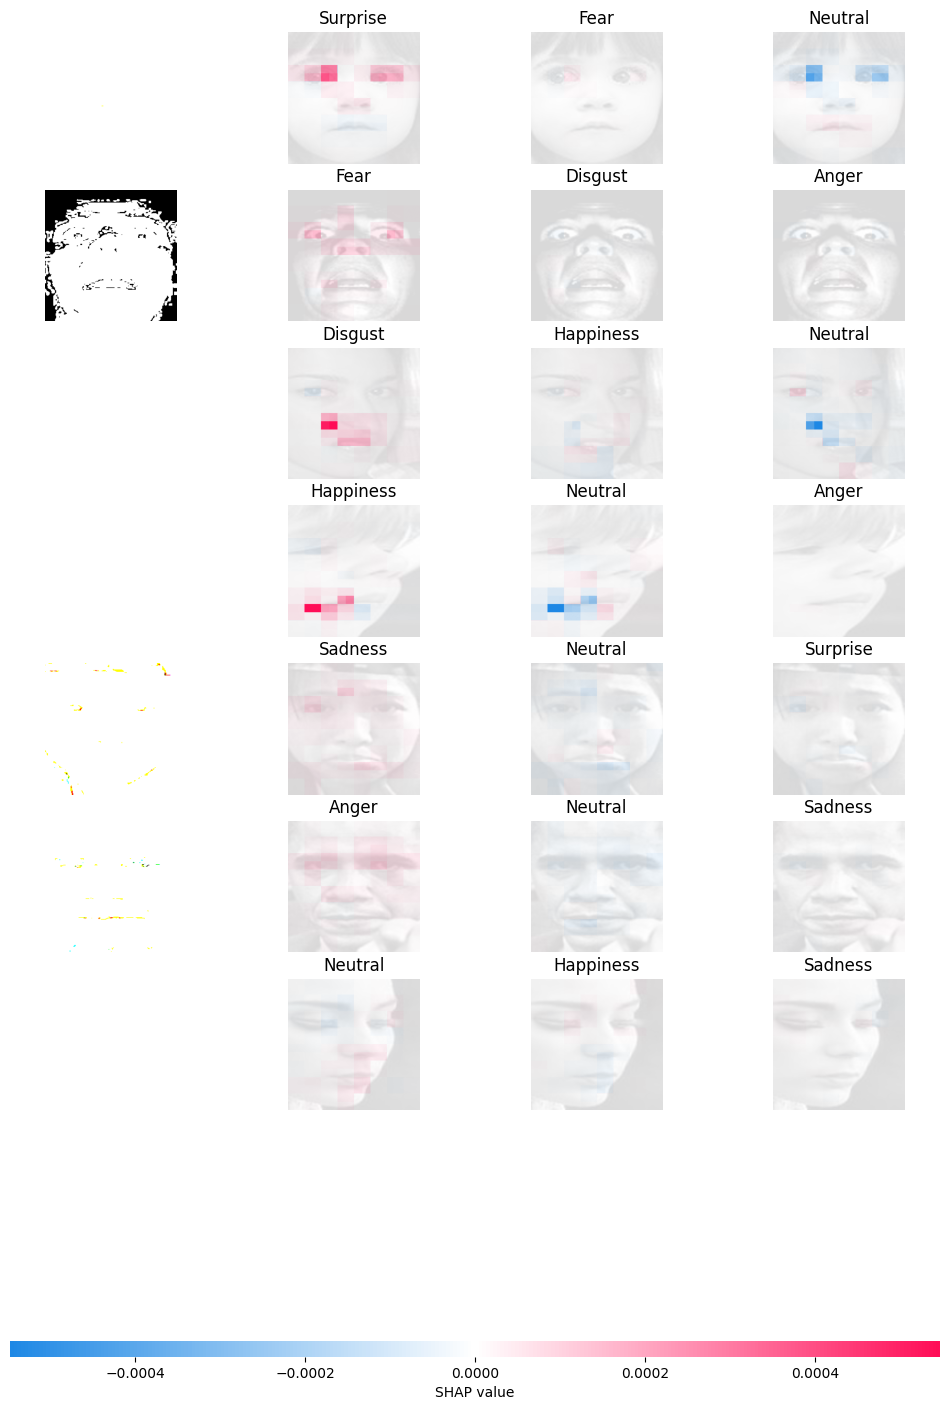

<Figure size 640x480 with 0 Axes>

In [16]:
xai_keys = [k for k in sorted(RUN_STORE) if k[0] == "ViT-B-CLIP" and os.path.exists(f"{CKPT_DIR}/{k[0]}_s{k[1]}.pt")]
assert xai_keys, "No saved ViT-B-CLIP checkpoint found on Drive."
XAI_KEY = xai_keys[0]; print("Explaining ViT-B-CLIP, seed", XAI_KEY[1])
xai_model = load_ckpt(f"{CKPT_DIR}/{XAI_KEY[0]}_s{XAI_KEY[1]}.pt")[0].eval()

def predict_np(imgs):                                           # imgs: (N, 224, 224, 3) uint8 or float in 0..255
    x = torch.as_tensor(np.asarray(imgs), dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    out = []
    with torch.no_grad():
        for i in range(0, len(x), 64):
            with autocast(): out.append(F.softmax(xai_model(x[i:i + 64].to(DEVICE)).float(), 1).cpu().numpy())
    return np.concatenate(out)

def to_img(i):                                                  # test face i as a 224x224 uint8 array
    return (prep_eval(Xte[i:i + 1])[0].permute(1, 2, 0).cpu().numpy() * 255).round().astype(np.uint8)

xai_imgs = []                                                   # one correctly classified test face per emotion
for c in range(NUM_CLASSES):
    for i in np.where(yt_np == c)[0]:
        im = to_img(i)
        if predict_np(im[None])[0].argmax() == c: xai_imgs.append(im); break
xai_imgs = np.stack(xai_imgs); print("images:", xai_imgs.shape)

import shap
masker = shap.maskers.Image("blur(64,64)", (IMG_SIZE, IMG_SIZE, 3))
shap_explainer = shap.Explainer(predict_np, masker, output_names=CLASSES)
sv = shap_explainer(xai_imgs.astype(np.float32), max_evals=1000, batch_size=50, outputs=shap.Explanation.argsort.flip[:3])
shap.image_plot(sv); plt.savefig(f"{OUT_DIR}/shap_explanations.png", dpi=200, bbox_inches="tight")

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

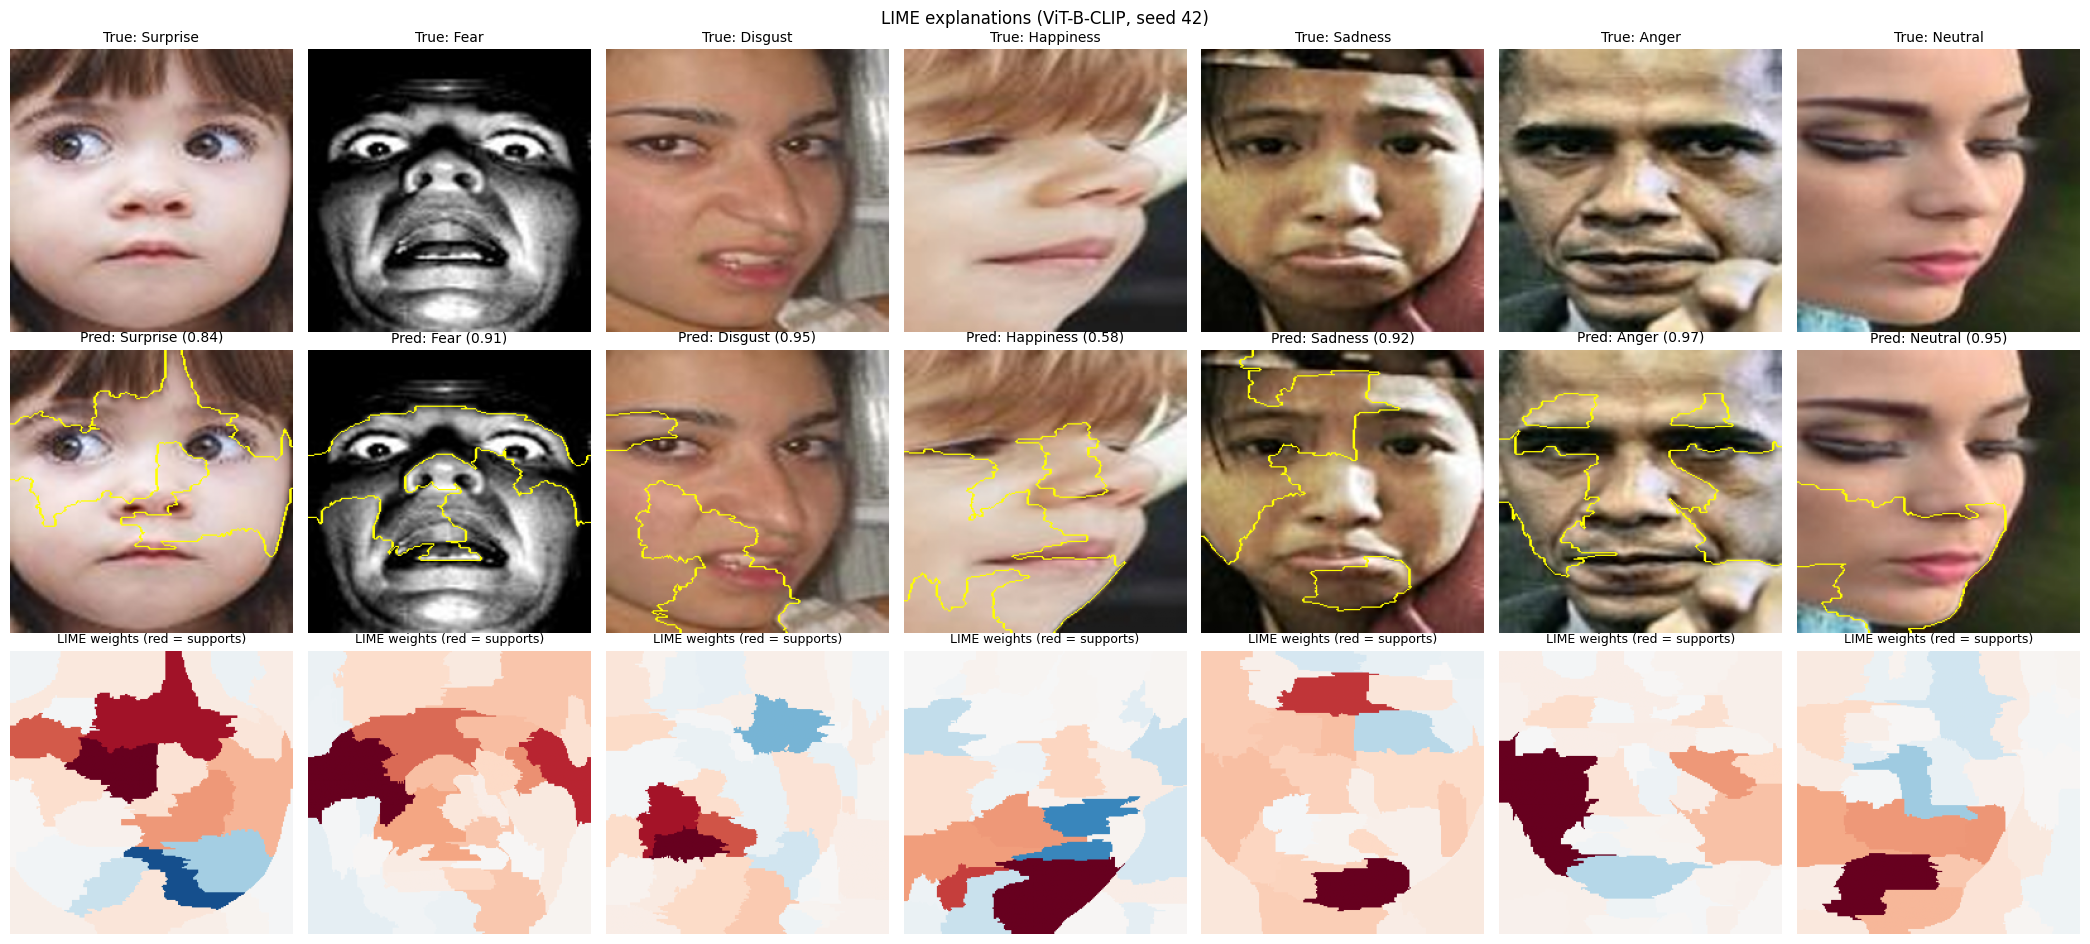

In [17]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

lime_explainer = lime_image.LimeImageExplainer(random_state=SEED)
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 9.6))
for i in range(NUM_CLASSES):
    img = xai_imgs[i]
    exp = lime_explainer.explain_instance(img, predict_np, top_labels=3, hide_color=0, num_samples=1500, batch_size=64)
    lab = exp.top_labels[0]; conf = predict_np(img[None])[0, lab]
    temp, mask = exp.get_image_and_mask(lab, positive_only=True, num_features=6, hide_rest=False)
    wmap = np.zeros(exp.segments.shape, dtype=np.float32)
    for seg, w in exp.local_exp[lab]: wmap[exp.segments == seg] = w
    lim = np.abs(wmap).max() + 1e-9
    axes[0, i].imshow(img); axes[0, i].set_title(f"True: {CLASSES[i]}", fontsize=10); axes[0, i].axis("off")
    axes[1, i].imshow(mark_boundaries(temp / 255.0, mask)); axes[1, i].set_title(f"Pred: {CLASSES[lab]} ({conf:.2f})", fontsize=10); axes[1, i].axis("off")
    axes[2, i].imshow(wmap, cmap="RdBu_r", vmin=-lim, vmax=lim); axes[2, i].set_title("LIME weights (red = supports)", fontsize=9); axes[2, i].axis("off")
plt.suptitle(f"LIME explanations (ViT-B-CLIP, seed {XAI_KEY[1]})"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/lime_explanations.png", dpi=200); plt.show()

## 9. Summary and download

In [18]:
b = metrics_df.iloc[0]
print(f"Best model: {b.Model} | accuracy {b.Accuracy:.4f} | macro P/R/F1 {b['Macro Precision']:.4f}/{b['Macro Recall']:.4f}/{b['Macro F1']:.4f}"
      f" | weighted P/R/F1 {b['Weighted Precision']:.4f}/{b['Weighted Recall']:.4f}/{b['Weighted F1']:.4f} | ROC-AUC {b['ROC-AUC (OvR)']:.4f} | MCC {b['MCC']:.4f}")
for k, P in ENS_T.items(): print(f"  ensemble mode {k:28s} accuracy {accuracy_score(yt_np, P.argmax(1)):.4f}")
r = mean_df.loc["Run ensemble"]; s = std_df.loc["Run ensemble"]
print(f"Run ensemble over {len(SEEDS)} seeds: accuracy {r.Accuracy:.4f} ± {s.Accuracy:.4f}")
weak = per_class_df[per_class_df.Model == BEST].sort_values("F1").head(2)
print("Hardest classes:", ", ".join(f"{a} (F1 {f:.2f})" for a, f in zip(weak.Class, weak.F1)))
shutil.make_archive("/content/rafdb_results", "zip", OUT_DIR); shutil.copy("/content/rafdb_results.zip", f"{CKPT_DIR}/rafdb_results.zip")
print("Results zip saved to Drive:", f"{CKPT_DIR}/rafdb_results.zip")
try:
    from google.colab import files; files.download("/content/rafdb_results.zip")
except Exception as e: print("Download skipped:", e)

Best model: Ens: Soft vote (greedy weighted) | accuracy 0.9032 | macro P/R/F1 0.8492/0.8341/0.8410 | weighted P/R/F1 0.9027/0.9032/0.9026 | ROC-AUC 0.9858 | MCC 0.8727
  ensemble mode Soft vote (equal)            accuracy 0.8996
  ensemble mode Soft vote (greedy weighted)  accuracy 0.9032
  ensemble mode Hard vote                    accuracy 0.9025
  ensemble mode Stacking (LogReg)            accuracy 0.8950
Run ensemble over 5 seeds: accuracy 0.8985 ± 0.0018
Hardest classes: Fear (F1 0.69), Disgust (F1 0.70)
Results zip saved to Drive: /content/drive/MyDrive/rafdb_transformers/rafdb_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TABLE 1: OVERALL TEST-SET METRICS (RAF-DB), sorted by accuracy
Inference time = ms per image including 4 TTA views; for averaged/ensemble rows, train and inference times are SUMMED over all member models.


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),Weighted-F1,ROC-AUC (OvR),MCC,Training Time (min),Inference Time (ms/img)
Rank,,,,,,,,,,,,
1,Ens: Soft vote (greedy weighted),0.9032,0.8492,0.8341,0.8410,0.9027,0.9032,0.9026,0.9858,0.8727,76.8998,44.8875
2,Ens: Hard vote,0.9025,0.8496,0.8405,0.8448,0.9029,0.9025,0.9025,0.9863,0.8720,148.9605,88.7909
3,ViT-B-CLIP (5-run avg),0.9003,0.8441,0.8350,0.8391,0.9003,0.9003,0.9000,0.9856,0.8690,84.8575,48.6037
4,Ens: Soft vote (equal),0.8996,0.8435,0.8316,0.8371,0.8997,0.8996,0.8994,0.9867,0.8681,148.9605,88.7909
5,Ens: Stacking (LogReg),0.8950,0.8416,0.8166,0.8264,0.8951,0.8950,0.8944,0.9833,0.8620,148.9605,88.7909
6,ViT-B-CLIP (seed 42),0.8944,0.8395,0.8292,0.8335,0.8946,0.8944,0.8942,0.9775,0.8613,17.0813,9.7017
7,ConvNeXt-Tiny (5-run avg),0.8856,0.8290,0.8199,0.8237,0.8874,0.8856,0.8861,0.9788,0.8499,45.2762,29.9316
8,BEiT-Base (seed 42),0.8801,0.8161,0.8130,0.8144,0.8810,0.8801,0.8804,0.9805,0.8426,18.8268,10.2556
9,ConvNeXt-Tiny (seed 42),0.8781,0.8203,0.8150,0.8170,0.8798,0.8781,0.8787,0.9738,0.8400,9.3929,5.9863



TABLE 2: PER-CLASS PRECISION / RECALL / F1 (all models)


Class                             Surprise                      Fear                   Disgust                 Happiness                   Sadness                     Anger                   Neutral                
Metric                           Precision  Recall      F1 Precision  Recall      F1 Precision  Recall      F1 Precision  Recall      F1 Precision  Recall      F1 Precision  Recall      F1 Precision  Recall      F1
Model                                                                                                                                                                                                                 
Ens: Soft vote (greedy weighted)    0.9052  0.8997  0.9024    0.7206  0.6622  0.6901    0.7518  0.6625  0.7043    0.9700  0.9561  0.9630    0.8745  0.9038  0.8889    0.8509  0.8457  0.8483    0.8717  0.9088  0.8898
Ens: Hard vote                      0.9043  0.8906  0.8974    0.7391  0.6892  0.7133    0.7255  0.6938  0.7093    0.9741  0.9536  0.9638    0.8737  0.8975  0.8854    0.8625  0.8519  0.8571    0.8678  0.9074  0.8871
ViT-B-CLIP (5-run avg)              0.8943  0.8997  0.8970    0.7143  0.6757  0.6944    0.7431  0.6688  0.7039    0.9732  0.9511  0.9620    0.8704  0.8996  0.8848    0.8457  0.8457  0.8457    0.8674  0.9044  0.8855
Ens: Soft vote (equal)              0.8960  0.8906  0.8933    0.6957  0.6486  0.6713    0.7483  0.6875  0.7166    0.9724  0.9527  0.9625    0.8649  0.8975  0.8809    0.8608  0.8395  0.8500    0.8662  0.9044  0.8849
Ens: Stacking (LogReg)              0.8499  0.9119  0.8798    0.7778  0.5676  0.6562    0.6855  0.6812  0.6834    0.9692  0.9544  0.9617    0.8727  0.9038  0.8880    0.8627  0.8148  0.8381    0.8734  0.8824  0.8778
ViT-B-CLIP (seed 42)                0.8960  0.8906  0.8933    0.7538  0.6622  0.7050    0.7260  0.6625  0.6928    0.9706  0.9485  0.9595    0.8637  0.9017  0.8823    0.8070  0.8519  0.8288    0.8590  0.8868  0.8726
ConvNeXt-Tiny (5-run avg)           0.8716  0.8875  0.8795    0.7273  0.6486  0.6857    0.6471  0.6875  0.6667    0.9696  0.9418  0.9555    0.8621  0.8766  0.8693    0.8800  0.8148  0.8462    0.8451  0.8824  0.8633
BEiT-Base (seed 42)                 0.8645  0.8723  0.8684    0.6620  0.6351  0.6483    0.6772  0.6688  0.6730    0.9688  0.9443  0.9564    0.8357  0.8724  0.8536    0.8599  0.8333  0.8464    0.8448  0.8647  0.8547
ConvNeXt-Tiny (seed 42)             0.8903  0.8632  0.8765    0.7231  0.6351  0.6763    0.6491  0.6938  0.6707    0.9620  0.9392  0.9505    0.8556  0.8556  0.8556    0.8303  0.8457  0.8379    0.8317  0.8721  0.8514


Per-class Precision


Class,Surprise,Fear,Disgust,Happiness,Sadness,Anger,Neutral
Model,,,,,,,
Ens: Soft vote (greedy weighted),0.9052,0.7206,0.7518,0.9700,0.8745,0.8509,0.8717
Ens: Hard vote,0.9043,0.7391,0.7255,0.9741,0.8737,0.8625,0.8678
ViT-B-CLIP (5-run avg),0.8943,0.7143,0.7431,0.9732,0.8704,0.8457,0.8674
Ens: Soft vote (equal),0.8960,0.6957,0.7483,0.9724,0.8649,0.8608,0.8662
Ens: Stacking (LogReg),0.8499,0.7778,0.6855,0.9692,0.8727,0.8627,0.8734
ViT-B-CLIP (seed 42),0.8960,0.7538,0.7260,0.9706,0.8637,0.8070,0.8590
ConvNeXt-Tiny (5-run avg),0.8716,0.7273,0.6471,0.9696,0.8621,0.8800,0.8451
BEiT-Base (seed 42),0.8645,0.6620,0.6772,0.9688,0.8357,0.8599,0.8448
ConvNeXt-Tiny (seed 42),0.8903,0.7231,0.6491,0.9620,0.8556,0.8303,0.8317



Per-class Recall


Class,Surprise,Fear,Disgust,Happiness,Sadness,Anger,Neutral
Model,,,,,,,
Ens: Soft vote (greedy weighted),0.8997,0.6622,0.6625,0.9561,0.9038,0.8457,0.9088
Ens: Hard vote,0.8906,0.6892,0.6938,0.9536,0.8975,0.8519,0.9074
ViT-B-CLIP (5-run avg),0.8997,0.6757,0.6688,0.9511,0.8996,0.8457,0.9044
Ens: Soft vote (equal),0.8906,0.6486,0.6875,0.9527,0.8975,0.8395,0.9044
Ens: Stacking (LogReg),0.9119,0.5676,0.6812,0.9544,0.9038,0.8148,0.8824
ViT-B-CLIP (seed 42),0.8906,0.6622,0.6625,0.9485,0.9017,0.8519,0.8868
ConvNeXt-Tiny (5-run avg),0.8875,0.6486,0.6875,0.9418,0.8766,0.8148,0.8824
BEiT-Base (seed 42),0.8723,0.6351,0.6688,0.9443,0.8724,0.8333,0.8647
ConvNeXt-Tiny (seed 42),0.8632,0.6351,0.6938,0.9392,0.8556,0.8457,0.8721



Per-class F1


Class,Surprise,Fear,Disgust,Happiness,Sadness,Anger,Neutral
Model,,,,,,,
Ens: Soft vote (greedy weighted),0.9024,0.6901,0.7043,0.9630,0.8889,0.8483,0.8898
Ens: Hard vote,0.8974,0.7133,0.7093,0.9638,0.8854,0.8571,0.8871
ViT-B-CLIP (5-run avg),0.8970,0.6944,0.7039,0.9620,0.8848,0.8457,0.8855
Ens: Soft vote (equal),0.8933,0.6713,0.7166,0.9625,0.8809,0.8500,0.8849
Ens: Stacking (LogReg),0.8798,0.6562,0.6834,0.9617,0.8880,0.8381,0.8778
ViT-B-CLIP (seed 42),0.8933,0.7050,0.6928,0.9595,0.8823,0.8288,0.8726
ConvNeXt-Tiny (5-run avg),0.8795,0.6857,0.6667,0.9555,0.8693,0.8462,0.8633
BEiT-Base (seed 42),0.8684,0.6483,0.6730,0.9564,0.8536,0.8464,0.8547
ConvNeXt-Tiny (seed 42),0.8765,0.6763,0.6707,0.9505,0.8556,0.8379,0.8514


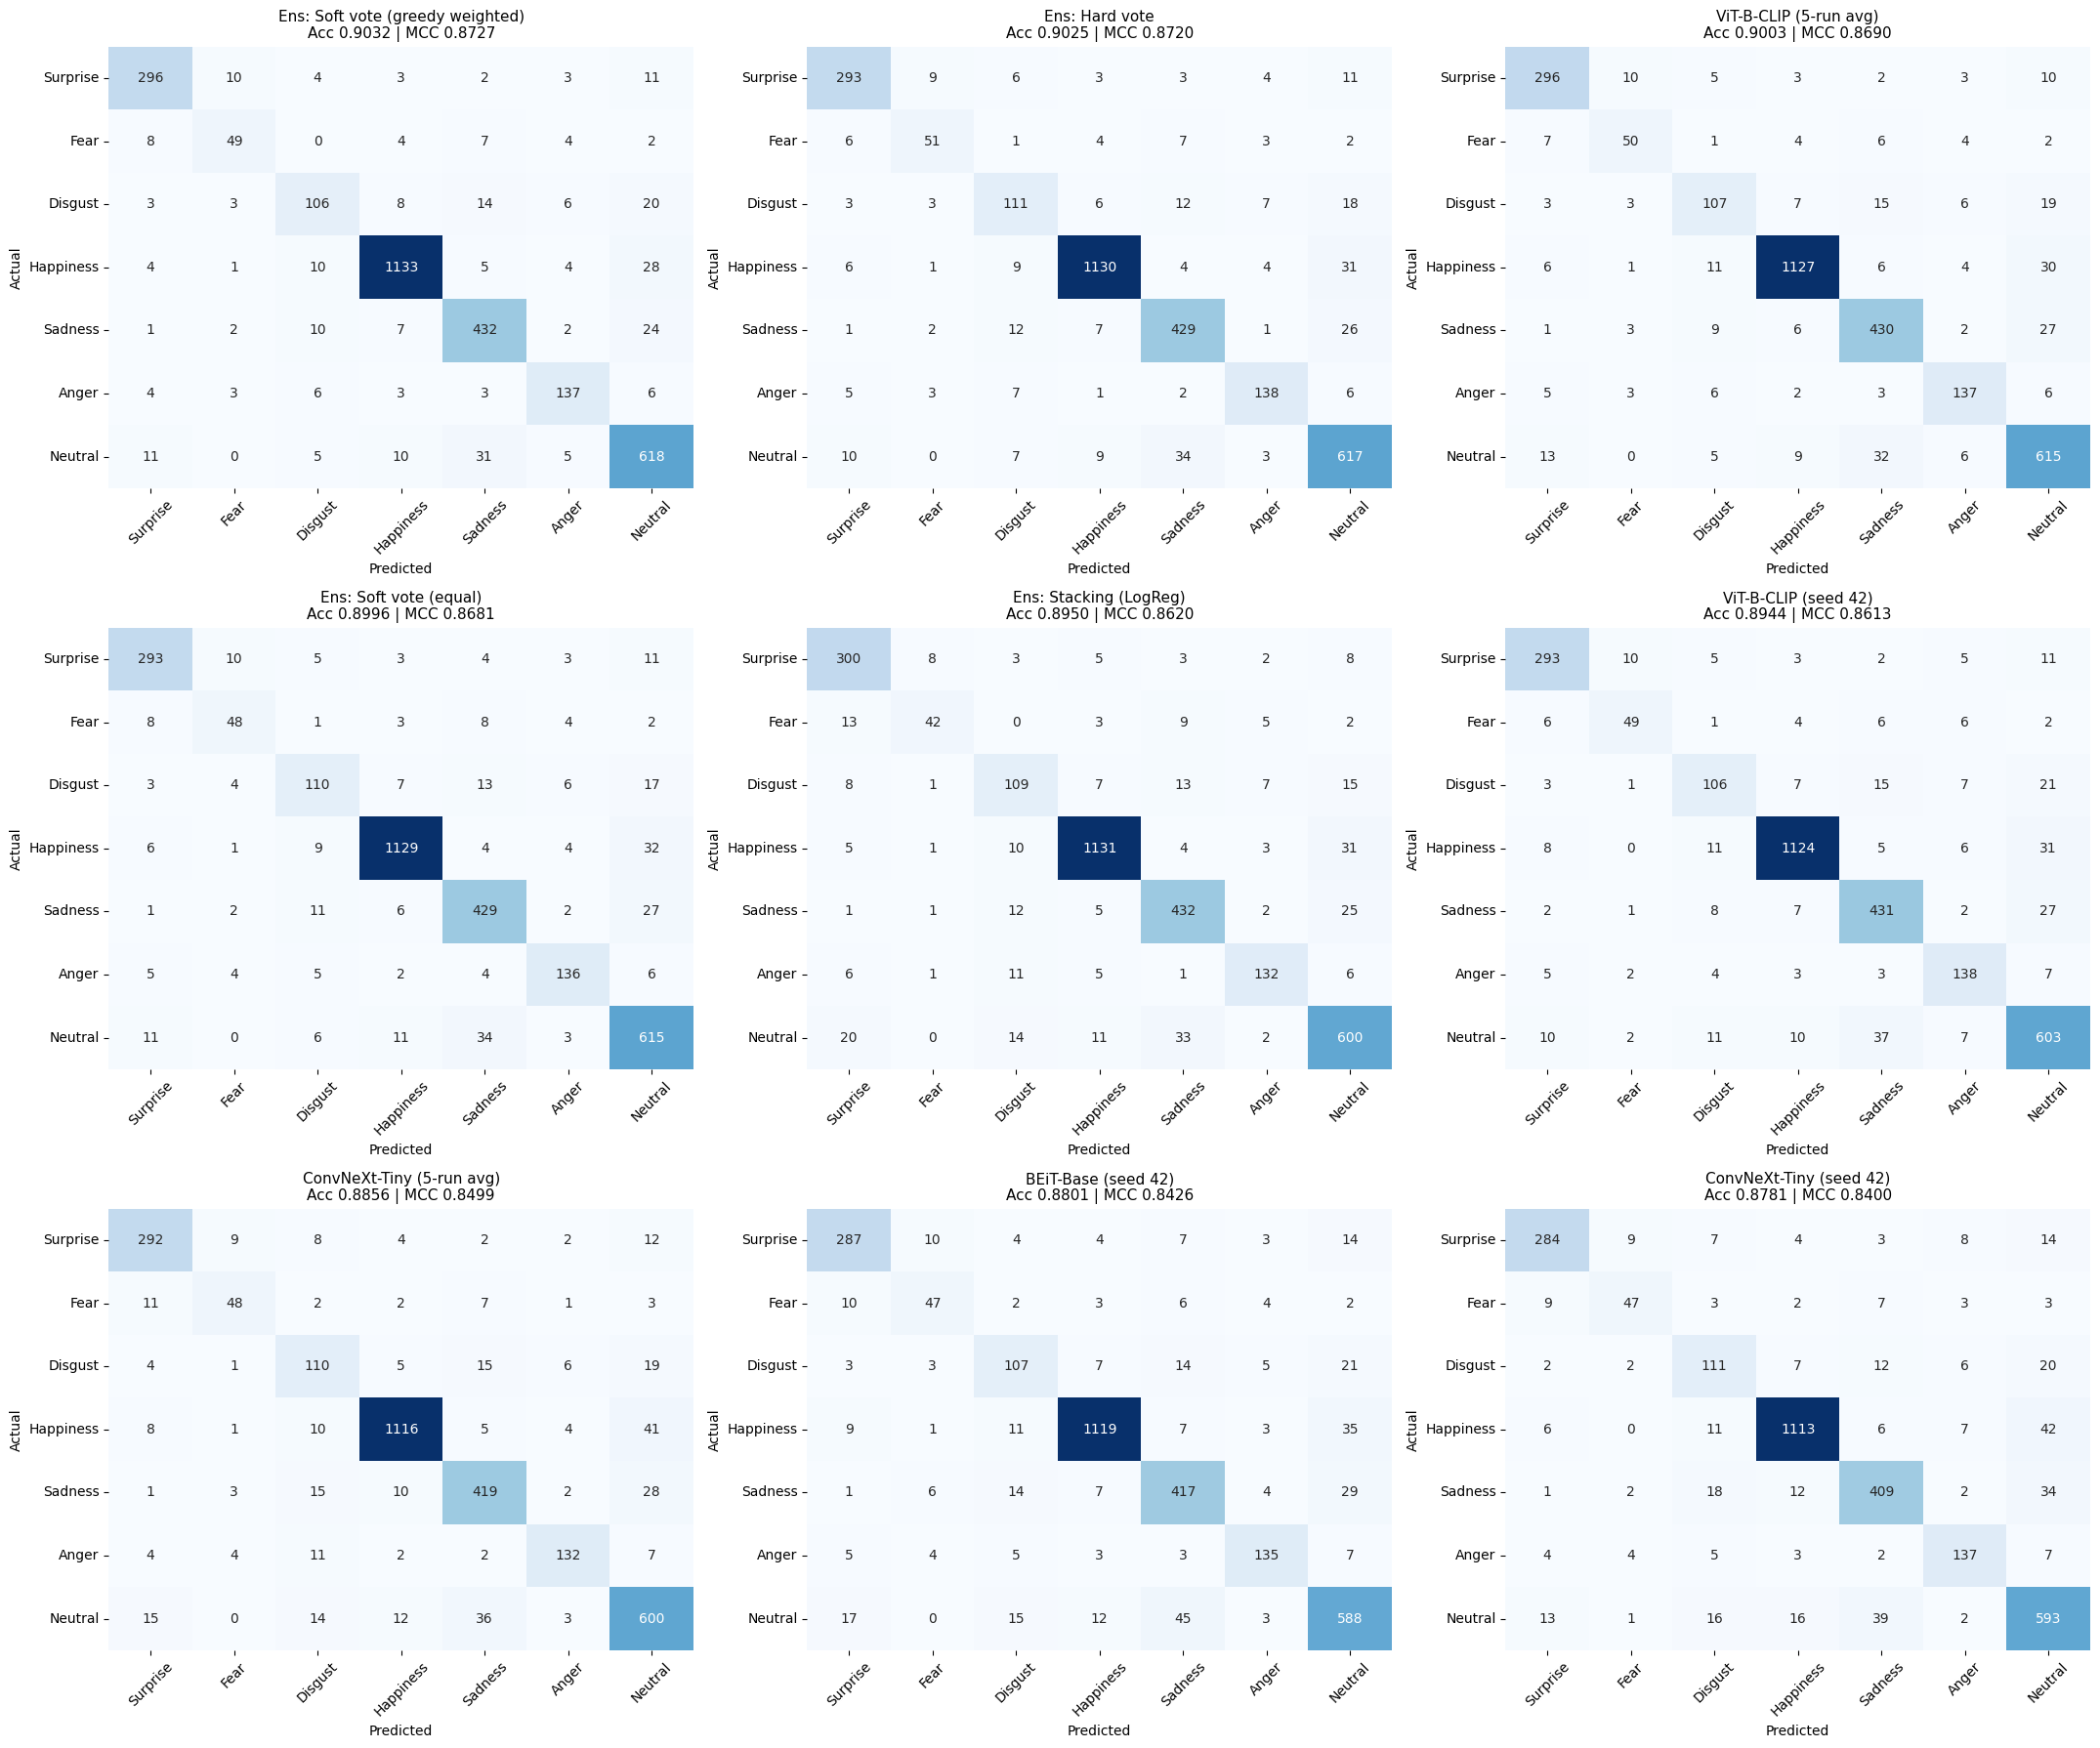


BEST MODEL: Ens: Soft vote (greedy weighted)


,Pred Surprise,Pred Fear,Pred Disgust,Pred Happiness,Pred Sadness,Pred Anger,Pred Neutral
True Surprise,296,10,4,3,2,3,11
True Fear,8,49,0,4,7,4,2
True Disgust,3,3,106,8,14,6,20
True Happiness,4,1,10,1133,5,4,28
True Sadness,1,2,10,7,432,2,24
True Anger,4,3,6,3,3,137,6
True Neutral,11,0,5,10,31,5,618


,Precision,Recall,F1
Class,,,
Surprise,0.9052,0.8997,0.9024
Fear,0.7206,0.6622,0.6901
Disgust,0.7518,0.6625,0.7043
Happiness,0.9700,0.9561,0.9630
Sadness,0.8745,0.9038,0.8889
Anger,0.8509,0.8457,0.8483
Neutral,0.8717,0.9088,0.8898



Saved to: /content/rafdb_results -> FINAL_summary_table.csv, FINAL_per_class_table.csv, FINAL_confusion_matrices_all.(png/csv), FINAL_all_results.xlsx


In [19]:
# ============================================================
# FINAL CONSOLIDATED SUMMARY (add as the LAST cell)
# Needs: EVAL_P, TT, II, yt_np, CLASSES, NUM_CLASSES, OUT_DIR, N_VIEWS (from earlier cells)
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix,
                             precision_recall_fscore_support)

pd.set_option("display.width", 300); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200)

def _norm(P):
    P = np.asarray(P, dtype=np.float64); return P / P.sum(1, keepdims=True)

# ---------- 1) MAIN SUMMARY TABLE: one row per model ----------
rows = []
for name, P in EVAL_P.items():
    P = _norm(P); pred = P.argmax(1)
    rows.append({
        "Model":                 name,
        "Accuracy":              accuracy_score(yt_np, pred),
        "Precision (Macro)":     precision_score(yt_np, pred, average="macro",    zero_division=0),
        "Recall (Macro)":        recall_score(yt_np, pred,    average="macro",    zero_division=0),
        "F1-Score (Macro)":      f1_score(yt_np, pred,        average="macro",    zero_division=0),
        "Precision (Weighted)":  precision_score(yt_np, pred, average="weighted", zero_division=0),
        "Recall (Weighted)":     recall_score(yt_np, pred,    average="weighted", zero_division=0),
        "Weighted-F1":           f1_score(yt_np, pred,        average="weighted", zero_division=0),
        "ROC-AUC (OvR)":         roc_auc_score(yt_np, P, multi_class="ovr", average="macro"),
        "MCC":                   matthews_corrcoef(yt_np, pred),
        "Training Time (min)":   TT[name] / 60,
        "Inference Time (ms/img)": II[name],
    })
summary_df = (pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True))
summary_df.index = summary_df.index + 1; summary_df.index.name = "Rank"

print("=" * 120)
print("TABLE 1: OVERALL TEST-SET METRICS (RAF-DB), sorted by accuracy")
print(f"Inference time = ms per image including {N_VIEWS} TTA views; for averaged/ensemble rows, train and inference times are SUMMED over all member models.")
print("=" * 120)
display(summary_df.round(4))
summary_df.to_csv(f"{OUT_DIR}/FINAL_summary_table.csv")

# ---------- 2) PER-CLASS PRECISION / RECALL / F1 for EVERY model ----------
pc_rows = []
for name, P in EVAL_P.items():
    pred = _norm(P).argmax(1)
    p, r, f, s = precision_recall_fscore_support(yt_np, pred, labels=range(NUM_CLASSES), zero_division=0)
    row = {"Model": name}
    for i, c in enumerate(CLASSES):
        row[(c, "Precision")] = p[i]; row[(c, "Recall")] = r[i]; row[(c, "F1")] = f[i]
    pc_rows.append(row)
pc_wide = pd.DataFrame(pc_rows).set_index("Model")
pc_wide.columns = pd.MultiIndex.from_tuples(pc_wide.columns, names=["Class", "Metric"])
pc_wide = pc_wide.loc[summary_df["Model"]]                       # same order as Table 1

print("\n" + "=" * 120); print("TABLE 2: PER-CLASS PRECISION / RECALL / F1 (all models)"); print("=" * 120)
display(pc_wide.round(4)); pc_wide.to_csv(f"{OUT_DIR}/FINAL_per_class_table.csv")

# One separate, easy-to-read table per metric (models x classes)
for m in ["Precision", "Recall", "F1"]:
    t = pc_wide.xs(m, axis=1, level="Metric")[CLASSES]
    print(f"\nPer-class {m}"); display(t.round(4))

# ---------- 3) CONFUSION MATRICES for EVERY model ----------
model_order = list(summary_df["Model"]); n = len(model_order)
ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7.2 * ncols, 6 * nrows)); axes = np.atleast_1d(axes).ravel()
cm_store = {}
for ax, name in zip(axes, model_order):
    pred = _norm(EVAL_P[name]).argmax(1); cm = confusion_matrix(yt_np, pred, labels=range(NUM_CLASSES)); cm_store[name] = cm
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(f"{name}\nAcc {accuracy_score(yt_np, pred):.4f} | MCC {matthews_corrcoef(yt_np, pred):.4f}", fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.tick_params(axis="x", rotation=45)
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/FINAL_confusion_matrices_all.png", dpi=200); plt.show()

# Confusion matrices also saved as numbers (one long CSV) so they can go into a paper/report
cm_rows = []
for name, cm in cm_store.items():
    df = pd.DataFrame(cm, index=[f"True {c}" for c in CLASSES], columns=[f"Pred {c}" for c in CLASSES]); df.insert(0, "Model", name); cm_rows.append(df)
pd.concat(cm_rows).to_csv(f"{OUT_DIR}/FINAL_confusion_matrices_all.csv")

# ---------- 4) BEST MODEL: full detail ----------
best_name = summary_df.iloc[0]["Model"]; bp = _norm(EVAL_P[best_name]).argmax(1)
print("\n" + "=" * 120); print(f"BEST MODEL: {best_name}"); print("=" * 120)
display(pd.DataFrame(cm_store[best_name], index=[f"True {c}" for c in CLASSES], columns=[f"Pred {c}" for c in CLASSES]))
display(pc_wide.loc[[best_name]].T.unstack("Metric").droplevel(0, axis=1).round(4) if False else
        pd.DataFrame({m: pc_wide.xs(m, axis=1, level="Metric").loc[best_name] for m in ["Precision", "Recall", "F1"]}).round(4))

# ---------- 5) One Excel file with everything ----------
with pd.ExcelWriter(f"{OUT_DIR}/FINAL_all_results.xlsx") as xw:
    summary_df.round(4).to_excel(xw, sheet_name="Overall metrics")
    pc_wide.round(4).to_excel(xw, sheet_name="Per-class")
    for name, cm in cm_store.items():
        pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_excel(xw, sheet_name=("CM " + name)[:31].replace(":", "").replace("/", ""))
print("\nSaved to:", OUT_DIR, "-> FINAL_summary_table.csv, FINAL_per_class_table.csv, FINAL_confusion_matrices_all.(png/csv), FINAL_all_results.xlsx")